In [ ]:
!pip -q install -U \
    "datasets<3.0.0" \
    transformers \
    accelerate \
    evaluate \
    jiwer \
    soundfile \
    librosa \
    sentencepiece \
    huggingface_hub

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("⚠️ No hay GPU disponible.")
    print("Ve a Runtime > Change runtime type > GPU")

PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: NVIDIA A100-SXM4-80GB
VRAM: 79.25 GB


In [ ]:
from datasets import get_dataset_config_names, load_dataset
from huggingface_hub import login
import os

# Try to get the Hugging Face token from Colab secrets
try:
    from google.colab import userdata
    hf_token = userdata.get("HUGGING_FACE")
except Exception:
    hf_token = os.environ.get("HUGGING_FACE")

if hf_token:
    print("Logging in to Hugging Face...")
    login(token=hf_token)
else:
    print("Warning: HUGGING_FACE token not found in secrets. Downloads might be slower or rate-limited.")

print("Fetching all FLEURS language configurations...")
all_fleurs_langs = get_dataset_config_names("google/fleurs")

LANGUAGES = {}

print("Building LANGUAGES dictionary...")
for lang_code in all_fleurs_langs:
    # Extract basic 2-letter code for models that require it (like Qwen)
    base_code = lang_code.split("_")[0]

    LANGUAGES[lang_code] = {
        "name": lang_code,  # Fast fallback name without downloading anything
        "qwen": base_code,
        "omni": lang_code,
        "seamless": base_code # Note: Seamless typically uses 3-letter codes, this is a fallback
    }

print(f"\nSuccessfully configured {len(LANGUAGES)} languages almost instantly!")
# Display a preview of the first 5 languages
print("Preview:", dict(list(LANGUAGES.items())[:5]))

Logging in to Hugging Face...
Fetching all FLEURS language configurations...


Building LANGUAGES dictionary...

Successfully configured 103 languages almost instantly!
Preview: {'af_za': {'name': 'af_za', 'qwen': 'af', 'omni': 'af_za', 'seamless': 'af'}, 'all': {'name': 'all', 'qwen': 'all', 'omni': 'all', 'seamless': 'all'}, 'am_et': {'name': 'am_et', 'qwen': 'am', 'omni': 'am_et', 'seamless': 'am'}, 'ar_eg': {'name': 'ar_eg', 'qwen': 'ar', 'omni': 'ar_eg', 'seamless': 'ar'}, 'as_in': {'name': 'as_in', 'qwen': 'as', 'omni': 'as_in', 'seamless': 'as'}}


In [ ]:
SAMPLES_PER_LANGUAGE = 50

SEED = 42

print("Muestras por idioma:", SAMPLES_PER_LANGUAGE)
print("Total de audios:", len(LANGUAGES) * SAMPLES_PER_LANGUAGE)

Muestras por idioma: 50
Total de audios: 5150


In [ ]:
from datasets import load_dataset

datasets_fleurs = {}

# Filtrar 'all' si no lo necesitas, o dejarlo
for lang_code, info in LANGUAGES.items():
    if lang_code == "all":
        continue

    print("=" * 60)
    print(f"Procesando (Streaming): {info['name']} ({lang_code})")

    try:
        # streaming=True evita descargar todo el dataset al disco
        # Se eliminó trust_remote_code=True ya que FLEURS ahora usa Parquet y datasets>=3.0 lo rechaza
        ds = load_dataset(
            "google/fleurs",
            lang_code,
            split="test",
            streaming=True
        )

        # Mezclar usando un buffer y tomar la cantidad deseada
        ds = ds.shuffle(seed=SEED, buffer_size=500).take(SAMPLES_PER_LANGUAGE)

        # Convertir a lista para mantenerlo en RAM y no volver a streamear
        muestras = list(ds)
        datasets_fleurs[lang_code] = muestras

        print("Muestras en RAM:", len(muestras))
    except Exception as e:
        print(f"Error cargando {lang_code}: {e}")

print("\n FLEURS completed.")

Procesando (Streaming): af_za (af_za)
Muestras en RAM: 50
Procesando (Streaming): am_et (am_et)
Muestras en RAM: 50
Procesando (Streaming): ar_eg (ar_eg)
Muestras en RAM: 50
Procesando (Streaming): as_in (as_in)
Muestras en RAM: 50
Procesando (Streaming): ast_es (ast_es)
Muestras en RAM: 50
Procesando (Streaming): az_az (az_az)
Muestras en RAM: 50
Procesando (Streaming): be_by (be_by)
Muestras en RAM: 50
Procesando (Streaming): bg_bg (bg_bg)
Muestras en RAM: 50
Procesando (Streaming): bn_in (bn_in)
Muestras en RAM: 50
Procesando (Streaming): bs_ba (bs_ba)
Muestras en RAM: 50
Procesando (Streaming): ca_es (ca_es)
Muestras en RAM: 50
Procesando (Streaming): ceb_ph (ceb_ph)
Muestras en RAM: 50
Procesando (Streaming): ckb_iq (ckb_iq)
Muestras en RAM: 50
Procesando (Streaming): cmn_hans_cn (cmn_hans_cn)
Muestras en RAM: 50
Procesando (Streaming): cs_cz (cs_cz)
Muestras en RAM: 50
Procesando (Streaming): cy_gb (cy_gb)
Muestras en RAM: 50
Procesando (Streaming): da_dk (da_dk)
Muestras en RAM:

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/google/fleurs/resolve/70bb2e84b976b7e960aa89f1c648e09c59f894dd/parquet-data/et_ee/test-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].


Muestras en RAM: 50
Procesando (Streaming): fa_ir (fa_ir)
Muestras en RAM: 50
Procesando (Streaming): ff_sn (ff_sn)
Muestras en RAM: 50
Procesando (Streaming): fi_fi (fi_fi)
Muestras en RAM: 50
Procesando (Streaming): fil_ph (fil_ph)
Muestras en RAM: 50
Procesando (Streaming): fr_fr (fr_fr)
Muestras en RAM: 50
Procesando (Streaming): ga_ie (ga_ie)
Muestras en RAM: 50
Procesando (Streaming): gl_es (gl_es)
Muestras en RAM: 50
Procesando (Streaming): gu_in (gu_in)
Muestras en RAM: 50
Procesando (Streaming): ha_ng (ha_ng)
Muestras en RAM: 50
Procesando (Streaming): he_il (he_il)
Muestras en RAM: 50
Procesando (Streaming): hi_in (hi_in)
Muestras en RAM: 50
Procesando (Streaming): hr_hr (hr_hr)
Muestras en RAM: 50
Procesando (Streaming): hu_hu (hu_hu)
Muestras en RAM: 50
Procesando (Streaming): hy_am (hy_am)
Muestras en RAM: 50
Procesando (Streaming): id_id (id_id)
Muestras en RAM: 50
Procesando (Streaming): ig_ng (ig_ng)
Muestras en RAM: 50
Procesando (Streaming): is_is (is_is)
Muestras en 

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/google/fleurs/resolve/70bb2e84b976b7e960aa89f1c648e09c59f894dd/parquet-data/umb_ao/test-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].


Muestras en RAM: 50
Procesando (Streaming): ur_pk (ur_pk)
Muestras en RAM: 50
Procesando (Streaming): uz_uz (uz_uz)
Muestras en RAM: 50
Procesando (Streaming): vi_vn (vi_vn)
Muestras en RAM: 50
Procesando (Streaming): wo_sn (wo_sn)
Muestras en RAM: 50
Procesando (Streaming): xh_za (xh_za)
Muestras en RAM: 50
Procesando (Streaming): yo_ng (yo_ng)
Muestras en RAM: 50
Procesando (Streaming): yue_hant_hk (yue_hant_hk)
Muestras en RAM: 50
Procesando (Streaming): zu_za (zu_za)
Muestras en RAM: 50

 FLEURS completed.


In [ ]:
lang_code = "es_419"

sample = datasets_fleurs[lang_code][0]

print("Idioma:", LANGUAGES[lang_code]["name"])
print("ID:", sample["id"])
print("Transcripción:")
print(sample["transcription"])

print("\nAudio:")
print(sample["audio"])

print("\nSampling rate:")
print(sample["audio"]["sampling_rate"])

Idioma: es_419
ID: 1839
Transcripción:
imagínese la pista de esquí como una ruta de senderismo

Audio:
{'path': '10728631300256730906.wav', 'array': array([ 0.        ,  0.        ,  0.        , ..., -0.00018376,
       -0.00017244, -0.00013667]), 'sampling_rate': 16000}

Sampling rate:
16000


In [ ]:
# ============================================================
# WHISPER LARGE-V3
# ============================================================

import torch
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1

whisper_pipe = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-large-v3",
    device=DEVICE,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)

print("Whisper Large-v3 completed")

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Whisper Large-v3 completed


In [ ]:
# ============================================================
# QWEN3-ASR
# ============================================================

from transformers import AutoProcessor, Qwen3ASRForConditionalGeneration

QWEN_MODEL = "Qwen/Qwen3-ASR-0.6B-hf"

qwen_processor = AutoProcessor.from_pretrained(QWEN_MODEL)

qwen_model = Qwen3ASRForConditionalGeneration.from_pretrained(
    QWEN_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)

qwen_model.eval()

print("Qwen3-ASR cargado")

processor_config.json:   0%|          | 0.00/487 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.56GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/165 [00:00<?, ?B/s]

Qwen3-ASR cargado


In [ ]:
import torch

# ============================================================
# DEVICE
# ============================================================

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Device:", device)

Device: cuda


In [ ]:

# ============================================================
#  OMNILINGUAL ASR - HUGGING FACE VERSION
# ============================================================

!pip install -q transformers accelerate sentencepiece


import torch

from transformers import (
    AutoProcessor,
    AutoModelForCTC
)

OMNI_MODEL = "aadel4/omniASR-CTC-300M"

omni_processor = AutoProcessor.from_pretrained(
    OMNI_MODEL
)

omni_model = AutoModelForCTC.from_pretrained(
    OMNI_MODEL
)

omni_model = omni_model.to(device)

omni_model.eval()

print("Omnilingual ASR cargado")
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/145k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Omnilingual ASR cargado
Device: cuda


In [ ]:
import torch
import numpy as np

def transcribe_seamless(audio_data, tgt_lang):
    """
    Procesa un solo audio usando SeamlessM4T.
    """
    audio = np.asarray(audio_data["array"], dtype=np.float32)
    sampling_rate = audio_data["sampling_rate"]

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)
    audio = np.squeeze(audio)

    inputs = processor(audio=audio, sampling_rate=sampling_rate, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(**inputs, tgt_lang=tgt_lang)

    prediction = processor.batch_decode(outputs, skip_special_tokens=True)[0]
    return prediction.strip()

def transcribe_seamless_batch(audio_list, tgt_lang):
    """
    Procesa una lista de audios en batch usando SeamlessM4T con padding.
    """
    processed_audios = []
    for audio_data in audio_list:
        arr = np.asarray(audio_data["array"], dtype=np.float32)
        if arr.ndim > 1:
            arr = np.mean(arr, axis=0)
        processed_audios.append(np.squeeze(arr))

    inputs = processor(audio=processed_audios, sampling_rate=16000, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(**inputs, tgt_lang=tgt_lang)

    predictions = processor.batch_decode(outputs, skip_special_tokens=True)
    return [p.strip() for p in predictions]

In [ ]:
# ============================================================
# SeamlessM4T
# ============================================================
!pip install -q transformers accelerate sentencepiece librosa soundfile

In [ ]:
import torch
from transformers import AutoProcessor, SeamlessM4Tv2ForSpeechToText

MODEL_NAME = "facebook/seamless-m4t-v2-large"

processor = AutoProcessor.from_pretrained(MODEL_NAME)

model = SeamlessM4Tv2ForSpeechToText.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

if torch.cuda.is_available():
    model = model.to("cuda")
elif torch.backends.mps.is_available():
    model = model.to("mps")
else:
    model = model.to("cpu")

print("Modelo cargado")

preprocessor_config.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.72k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/19.7k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B / 5.17MB            

tokenizer.model: downloading bytes:           |  0.00B            

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1429 [00:00<?, ?it/s]

[transformers] SeamlessM4Tv2ForSpeechToText LOAD REPORT from: facebook/seamless-m4t-v2-large
Key                                                                           | Status     |  | 
------------------------------------------------------------------------------+------------+--+-
text_encoder.layers.{0...23}.self_attn.out_proj.weight                        | UNEXPECTED |  | 
t2u_model.model.decoder.layers.{0, 1, 2, 3, 4, 5}.self_attn.v_proj.bias       | UNEXPECTED |  | 
text_encoder.layers.{0...23}.self_attn.k_proj.weight                          | UNEXPECTED |  | 
text_encoder.layers.{0...23}.self_attn_layer_norm.bias                        | UNEXPECTED |  | 
vocoder.hifi_gan.resblocks.{0...14}.convs1.{0, 1, 2}.weight                   | UNEXPECTED |  | 
t2u_model.model.decoder.embed_tokens.weight                                   | UNEXPECTED |  | 
vocoder.hifi_gan.resblocks.{0...14}.convs2.{0, 1, 2}.bias                     | UNEXPECTED |  | 
text_encoder.layers.{0...23}.self_

generation_config.json:   0%|          | 0.00/9.91M [00:00<?, ?B/s]

Modelo cargado


In [ ]:

import numpy as np

audio_files = {}

for lang_code, ds in datasets_fleurs.items():

    print(f"Preparando {lang_code}...")

    audio_files[lang_code] = []

    for i, sample in enumerate(ds):

        audio_files[lang_code].append(
            sample["audio"]
        )

    print(
        f"{lang_code}: "
        f"{len(audio_files[lang_code])} audios disponibles"
    )

print("\nAudios preparados correctamente")

Preparando af_za...
af_za: 50 audios disponibles
Preparando am_et...
am_et: 50 audios disponibles
Preparando ar_eg...
ar_eg: 50 audios disponibles
Preparando as_in...
as_in: 50 audios disponibles
Preparando ast_es...
ast_es: 50 audios disponibles
Preparando az_az...
az_az: 50 audios disponibles
Preparando be_by...
be_by: 50 audios disponibles
Preparando bg_bg...
bg_bg: 50 audios disponibles
Preparando bn_in...
bn_in: 50 audios disponibles
Preparando bs_ba...
bs_ba: 50 audios disponibles
Preparando ca_es...
ca_es: 50 audios disponibles
Preparando ceb_ph...
ceb_ph: 50 audios disponibles
Preparando ckb_iq...
ckb_iq: 50 audios disponibles
Preparando cmn_hans_cn...
cmn_hans_cn: 50 audios disponibles
Preparando cs_cz...
cs_cz: 50 audios disponibles
Preparando cy_gb...
cy_gb: 50 audios disponibles
Preparando da_dk...
da_dk: 50 audios disponibles
Preparando de_de...
de_de: 50 audios disponibles
Preparando el_gr...
el_gr: 50 audios disponibles
Preparando en_us...
en_us: 50 audios disponibles
Pr

In [ ]:
def transcribe_omnilingual(audio_data):

    audio = np.asarray(
        audio_data["array"],
        dtype=np.float32
    )

    sampling_rate = audio_data["sampling_rate"]

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    audio = np.squeeze(audio)

    if sampling_rate != 16000:

        audio_tensor = torch.tensor(audio)

        audio_tensor = torchaudio.functional.resample(
            audio_tensor,
            sampling_rate,
            16000
        )

        audio = audio_tensor.numpy()

    inputs = omni_processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        logits = omni_model(**inputs).logits

    predicted_ids = torch.argmax(logits, dim=-1)

    prediction = omni_processor.decode(
        predicted_ids[0]
    )

    return prediction.strip()

In [ ]:
# ============================================================
#  TEST WHISPER
# ============================================================

test_lang = "es_419"

# Pasamos una copia del diccionario para evitar que el pipeline lo vacíe (haga pop)
audio_path = audio_files[test_lang][0].copy()

result = whisper_pipe(
    audio_path,
    generate_kwargs={
        "language": "spanish",
        "task": "transcribe"
    }
)

print("Referencia:")
print(datasets_fleurs[test_lang][0]["transcription"])

print("\nWhisper:")
print(result["text"])

Referencia:
imagínese la pista de esquí como una ruta de senderismo

Whisper:
 Imagínese la pista de esquí como una ruta de senderismo.


In [ ]:
# ============================================================
# QWEN3-ASR Test
# ============================================================

import torch

def transcribe_qwen(audio_path, language):

    inputs = qwen_processor.apply_transcription_request(
        audio=audio_path,
        language=language
    )

    inputs = inputs.to(
        qwen_model.device,
        qwen_model.dtype
    )

    with torch.inference_mode():
        output_ids = qwen_model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False
        )

    generated_ids = output_ids[:, inputs["input_ids"].shape[1]:]

    decoded = qwen_processor.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    if isinstance(decoded, list):
        text = decoded[0]
    else:
        text = str(decoded)

    return text.strip()

In [ ]:
# Recargamos el idioma es_419 porque el diccionario original fue vaciado por Whisper
from datasets import load_dataset

lang_code = "es_419"
print(f"Recargando audios para {lang_code}...")

ds = load_dataset("google/fleurs", lang_code, split="test", streaming=True)
ds = ds.shuffle(seed=SEED, buffer_size=500).take(SAMPLES_PER_LANGUAGE)

# Sobrescribimos en la memoria
datasets_fleurs[lang_code] = list(ds)

# Reconstruimos audio_files para este idioma
audio_files[lang_code] = []
for sample in datasets_fleurs[lang_code]:
    audio_files[lang_code].append(sample["audio"])

print("¡Audios de es_419 recuperados con éxito!")

Recargando audios para es_419...
¡Audios de es_419 recuperados con éxito!


In [ ]:
# ============================================================
#  TEST OMNILINGUAL ASR
# ============================================================

omni_test = transcribe_omnilingual(
    audio_files["es_419"][0]
)

print("Referencia:")
print(
    datasets_fleurs["es_419"][0]["transcription"]
)

print("\nOmnilingual:")
print(omni_test)

Referencia:
imagínese la pista de esquí como una ruta de senderismo

Omnilingual:
imagínese la pista de esquí como una ruta de cenderismo


In [ ]:
import torch
import evaluate
import re
import unicodedata

def normalize_text(text):
    text = str(text).lower()
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

wer_metric = evaluate.load("wer")
seamless_results = []

# Mapeo básico de FLEURS (2-letras) a SeamlessM4T (3-letras)
SEAMLESS_LANG_MAP = {
    "af_za": "afr", "am_et": "amh", "ar_eg": "arb", "as_in": "asm", "az_az": "azj", "be_by": "bel", "bg_bg": "bul",
    "bn_in": "ben", "bs_ba": "bos", "ca_es": "cat", "ceb_ph": "ceb", "cs_cz": "ces", "ckb_iq": "ckb",
    "cmn_hans_cn": "cmn", "cy_gb": "cym", "da_dk": "dan", "de_de": "deu", "el_gr": "ell", "en_us": "eng",
    "es_419": "spa", "et_ee": "est", "fa_ir": "pes", "fi_fi": "fin", "fr_fr": "fra", "gl_es": "glg", "gu_in": "guj",
    "he_il": "heb", "hi_in": "hin", "hr_hr": "hrv", "hu_hu": "hun", "hy_am": "hye", "id_id": "ind", "is_is": "isl",
    "it_it": "ita", "ja_jp": "jpn", "jv_id": "jav", "ka_ge": "kat", "kk_kz": "kaz", "km_kh": "khm", "kn_in": "kan",
    "ko_kr": "kor", "lt_lt": "lit", "lv_lv": "lvs", "ml_in": "mal", "mr_in": "mar", "nl_nl": "nld", "pa_in": "pan",
    "pl_pl": "pol", "pt_br": "por", "ro_ro": "ron", "ru_ru": "rus", "sk_sk": "slk", "sl_si": "slv", "sv_se": "swe",
    "sw_ke": "swh", "ta_in": "tam", "te_in": "tel", "th_th": "tha", "tr_tr": "tur", "uk_ua": "ukr", "ur_pk": "urd",
    "vi_vn": "vie", "yue_hant_hk": "yue", "zu_za": "zul"
}

# Definir el tamaño del lote (ajustable según la VRAM)
BATCH_SIZE = 8

for lang_code, ds_lang in datasets_fleurs.items():
    info = LANGUAGES.get(lang_code, {"name": lang_code})

    # Intentamos obtener el código mapeado o un fallback seguro
    tgt_lang = SEAMLESS_LANG_MAP.get(lang_code, info.get("seamless", "eng"))

    print(f"Evaluando SeamlessM4T para {info['name']} ({lang_code}) con tgt_lang={tgt_lang} en Lotes de {BATCH_SIZE}...")

    predictions = []
    references = []

    # Procesamiento por lotes (Batching)
    for i in range(0, len(ds_lang), BATCH_SIZE):
        batch = ds_lang[i:i + BATCH_SIZE]

        audio_arrays = [item["audio"]["array"] for item in batch]
        refs = [item["transcription"] for item in batch]

        try:
            # El procesador automáticamente añade padding al lote
            inputs = processor(
                audio=audio_arrays,
                sampling_rate=16000,
                return_tensors="pt",
                padding=True
            ).to(device)

            with torch.no_grad():
                outputs = model.generate(**inputs, tgt_lang=tgt_lang)

            preds = processor.batch_decode(outputs, skip_special_tokens=True)

            for pred, ref in zip(preds, refs):
                predictions.append(normalize_text(pred))
                references.append(normalize_text(ref))

        except Exception as e:
            print(f"  ⚠️ Error en batch para idioma {lang_code}: {str(e)[:150]}")
            break # Salimos del bucle si el lote falla

    if predictions and len(predictions) == len(ds_lang):
        wer_score = wer_metric.compute(predictions=predictions, references=references)
    else:
        wer_score = None

    seamless_results.append({
        "language": info["name"],
        "lang_code": lang_code,
        "model": "SeamlessM4T",
        "wer": float(wer_score) if wer_score is not None else None
    })

print("\nSeamlessM4T completed")

Evaluando SeamlessM4T para af_za (af_za) con tgt_lang=afr en Lotes de 8...
Evaluando SeamlessM4T para am_et (am_et) con tgt_lang=amh en Lotes de 8...
Evaluando SeamlessM4T para ar_eg (ar_eg) con tgt_lang=arb en Lotes de 8...
Evaluando SeamlessM4T para as_in (as_in) con tgt_lang=asm en Lotes de 8...
Evaluando SeamlessM4T para ast_es (ast_es) con tgt_lang=ast en Lotes de 8...
  ⚠️ Error en batch para idioma ast_es: `tgt_lang=ast` is not supported by this model. Please specify a `tgt_lang` in
                        afr, amh, arb, ary, arz, asm, azj, bel, ben, bos
Evaluando SeamlessM4T para az_az (az_az) con tgt_lang=azj en Lotes de 8...
Evaluando SeamlessM4T para be_by (be_by) con tgt_lang=bel en Lotes de 8...
Evaluando SeamlessM4T para bg_bg (bg_bg) con tgt_lang=bul en Lotes de 8...
Evaluando SeamlessM4T para bn_in (bn_in) con tgt_lang=ben en Lotes de 8...
Evaluando SeamlessM4T para bs_ba (bs_ba) con tgt_lang=bos en Lotes de 8...
Evaluando SeamlessM4T para ca_es (ca_es) con tgt_lang=cat

In [ ]:
# Nomalization
import re
import unicodedata


def normalize_text(text):

    text = str(text).lower()

    text = unicodedata.normalize(
        "NFKC",
        text
    )

    text = re.sub(
        r"[^\w\s]",
        " ",
        text,
        flags=re.UNICODE
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [ ]:
# ============================================================
# Metric WER (validate if prefer use CER)
# ============================================================

import jiwer


def calculate_wer(reference, hypothesis):

    reference = normalize_text(reference)
    hypothesis = normalize_text(hypothesis)

    return jiwer.wer(
        reference,
        hypothesis
    )

In [ ]:
# ============================================================
# EVAL WHISPER (BATCHED)
# ============================================================

import pandas as pd
import time

results = []
BATCH_SIZE = 16

for lang_code, ds in datasets_fleurs.items():

    print("\n" + "=" * 70)
    print(f"Whisper -> {LANGUAGES[lang_code]['name']} (Batched)")
    print("=" * 70)

    # Prepare batch data
    audio_arrays = [sample["audio"]["array"] for sample in ds]
    references = [sample["transcription"] for sample in ds]
    sample_ids = [sample["id"] for sample in ds]

    start_time = time.time()

    try:
        # Feed the whole batch to the pipeline
        outputs = whisper_pipe(
            audio_arrays,
            batch_size=BATCH_SIZE,
            generate_kwargs={
                "task": "transcribe",
                "language": LANGUAGES[lang_code]["qwen"]
            }
        )

        elapsed_per_sample = (time.time() - start_time) / len(ds)

        for i, output in enumerate(outputs):
            hypothesis = output["text"]
            reference = references[i]
            error = calculate_wer(reference, hypothesis)

            results.append({
                "language_code": lang_code,
                "language": LANGUAGES[lang_code]["name"],
                "sample_id": sample_ids[i],
                "model": "Whisper-Large-v3",
                "reference": reference,
                "prediction": hypothesis,
                "wer": error,
                "time_seconds": elapsed_per_sample,
                "status": "OK",
            })

        print(f"{len(ds)}/{len(ds)} completados")

    except Exception as e:
        print(f"ERROR processing {lang_code}: {str(e)[:100]}")

print("\n Whisper finished")


Whisper -> af_za (Batched)
50/50 completados

Whisper -> am_et (Batched)
50/50 completados

Whisper -> ar_eg (Batched)
50/50 completados

Whisper -> as_in (Batched)
50/50 completados

Whisper -> ast_es (Batched)
ERROR processing ast_es: Unsupported language: ast. Language should be one of: ['english', 'chinese', 'german', 'spanish', 'r

Whisper -> az_az (Batched)
50/50 completados

Whisper -> be_by (Batched)
50/50 completados

Whisper -> bg_bg (Batched)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


50/50 completados

Whisper -> bn_in (Batched)
50/50 completados

Whisper -> bs_ba (Batched)
50/50 completados

Whisper -> ca_es (Batched)
50/50 completados

Whisper -> ceb_ph (Batched)
ERROR processing ceb_ph: The expanded size of the tensor (3000) must match the existing size (3294) at non-singleton dimensio

Whisper -> ckb_iq (Batched)
ERROR processing ckb_iq: Unsupported language: ckb. Language should be one of: ['english', 'chinese', 'german', 'spanish', 'r

Whisper -> cmn_hans_cn (Batched)
ERROR processing cmn_hans_cn: Unsupported language: cmn. Language should be one of: ['english', 'chinese', 'german', 'spanish', 'r

Whisper -> cs_cz (Batched)
50/50 completados

Whisper -> cy_gb (Batched)
50/50 completados

Whisper -> da_dk (Batched)
50/50 completados

Whisper -> de_de (Batched)
ERROR processing de_de: The expanded size of the tensor (3000) must match the existing size (3354) at non-singleton dimensio

Whisper -> el_gr (Batched)
50/50 completados

Whisper -> en_us (Batched)
50/5

In [ ]:
# ============================================================
# EVAL QWEN3-ASR (BATCHED & OPTIMIZED)
# ============================================================
import time
import torch

qwen_results = []
BATCH_SIZE = 8

for lang_code, ds in datasets_fleurs.items():

    print("\n" + "=" * 70)
    print(f"Qwen3-ASR -> {LANGUAGES[lang_code]['name']} (Batched)")
    print("=" * 70)

    ds_list = list(ds)
    # Nota: Qwen normalmente infiere el idioma si no se le pasa uno explicitamente en el processor base,
    # pero intentaremos pasarlo de forma general o confiar en el auto-detect si falla.

    for i in range(0, len(ds_list), BATCH_SIZE):
        batch = ds_list[i:i + BATCH_SIZE]

        audio_inputs = [sample["audio"]["array"] for sample in batch]
        references = [sample["transcription"] for sample in batch]
        sample_ids = [sample.get("id", i + j) for j, sample in enumerate(batch)]

        start_time = time.time()

        try:
            # Procesamiento en lote
            inputs = qwen_processor(
                audio=audio_inputs,
                sampling_rate=16000,
                return_tensors="pt",
                padding=True
            )
            inputs = inputs.to(qwen_model.device, qwen_model.dtype)

            with torch.inference_mode():
                output_ids = qwen_model.generate(
                    **inputs,
                    max_new_tokens=256,
                    do_sample=False
                )

            # Recortar los ids de entrada
            generated_ids = output_ids[:, inputs["input_ids"].shape[1]:]

            # Decodificar el lote completo
            decoded = qwen_processor.batch_decode(generated_ids, skip_special_tokens=True)

            elapsed_per_sample = (time.time() - start_time) / len(batch)

            for j, hypothesis in enumerate(decoded):
                norm_ref = normalize_text(references[j])
                norm_hyp = normalize_text(hypothesis)

                error = calculate_wer(norm_ref, norm_hyp)

                qwen_results.append({
                    "language_code": lang_code,
                    "language": LANGUAGES[lang_code]["name"],
                    "sample_id": sample_ids[j],
                    "model": "Qwen3-ASR-0.6B",
                    "reference": references[j],
                    "prediction": hypothesis.strip(),
                    "wer": error,
                    "time_seconds": elapsed_per_sample,
                    "status": "OK",
                })

        except Exception as e:
            if i == 0:
                print(f"  ⚠️ Error crítico en idioma {lang_code}: {str(e)[:150]}")
                print("  ⏩ Saltando las muestras restantes para este idioma...")

            # Rellenar con errores las muestras de este lote y romper el bucle del idioma
            for j, ref in enumerate(references):
                qwen_results.append({
                    "language_code": lang_code,
                    "language": LANGUAGES[lang_code]["name"],
                    "sample_id": sample_ids[j],
                    "model": "Qwen3-ASR-0.6B",
                    "reference": ref,
                    "prediction": "",
                    "wer": 1.0,
                    "time_seconds": 0.0,
                    "status": f"ERROR: {str(e)[:100]}",
                })
            break # Sale del batch-loop y avanza al siguiente idioma

        print(f"{min(i + BATCH_SIZE, len(ds_list))}/{len(ds_list)} completados")

print("\nQwen3-ASR finished")


Qwen3-ASR -> af_za (Batched)
  ⚠️ Error crítico en idioma af_za: Qwen3ASRProcessor.__call__() missing 1 required positional argument: 'text'
  ⏩ Saltando las muestras restantes para este idioma...

Qwen3-ASR -> am_et (Batched)
  ⚠️ Error crítico en idioma am_et: Qwen3ASRProcessor.__call__() missing 1 required positional argument: 'text'
  ⏩ Saltando las muestras restantes para este idioma...

Qwen3-ASR -> ar_eg (Batched)
  ⚠️ Error crítico en idioma ar_eg: Qwen3ASRProcessor.__call__() missing 1 required positional argument: 'text'
  ⏩ Saltando las muestras restantes para este idioma...

Qwen3-ASR -> as_in (Batched)
  ⚠️ Error crítico en idioma as_in: Qwen3ASRProcessor.__call__() missing 1 required positional argument: 'text'
  ⏩ Saltando las muestras restantes para este idioma...

Qwen3-ASR -> ast_es (Batched)
  ⚠️ Error crítico en idioma ast_es: Qwen3ASRProcessor.__call__() missing 1 required positional argument: 'text'
  ⏩ Saltando las muestras restantes para este idioma...

Qwen3-A

In [ ]:
# ============================================================
# EVAL SEAMLESSM4T (BATCHED)
# ============================================================

import time

# Mapeo comprensivo de FLEURS (2 letras) a SeamlessM4T (3 letras)
SEAMLESS_LANG_MAP = {
    "af_za": "afr", "am_et": "amh", "ar_eg": "arb", "as_in": "asm", "az_az": "azj", "be_by": "bel", "bg_bg": "bul",
    "bn_in": "ben", "bs_ba": "bos", "ca_es": "cat", "ceb_ph": "ceb", "cs_cz": "ces", "ckb_iq": "ckb",
    "cmn_hans_cn": "cmn", "cy_gb": "cym", "da_dk": "dan", "de_de": "deu", "el_gr": "ell", "en_us": "eng",
    "es_419": "spa", "et_ee": "est", "fa_ir": "pes", "fi_fi": "fin", "fr_fr": "fra", "gl_es": "glg", "gu_in": "guj",
    "he_il": "heb", "hi_in": "hin", "hr_hr": "hrv", "hu_hu": "hun", "hy_am": "hye", "id_id": "ind", "is_is": "isl",
    "it_it": "ita", "ja_jp": "jpn", "jv_id": "jav", "ka_ge": "kat", "kk_kz": "kaz", "km_kh": "khm", "kn_in": "kan",
    "ko_kr": "kor", "lt_lt": "lit", "lv_lv": "lvs", "ml_in": "mal", "mr_in": "mar", "nl_nl": "nld", "pa_in": "pan",
    "pl_pl": "pol", "pt_br": "por", "ro_ro": "ron", "ru_ru": "rus", "sk_sk": "slk", "sl_si": "slv", "sv_se": "swe",
    "sw_ke": "swh", "ta_in": "tam", "te_in": "tel", "th_th": "tha", "tr_tr": "tur", "uk_ua": "ukr", "ur_pk": "urd",
    "vi_vn": "vie", "yue_hant_hk": "yue", "zu_za": "zul"
}

seamless_results = []
BATCH_SIZE = 8

for lang_code, info in LANGUAGES.items():
    if lang_code not in datasets_fleurs:
        continue

    print("\n" + "=" * 70)
    print(f"Evaluando SeamlessM4T para {info['name']} ({lang_code}) en BATCH...")
    print("=" * 70)

    # Intentar obtener el mapeo explícito, si no, caer de vuelta al fallback general
    tgt_lang = SEAMLESS_LANG_MAP.get(lang_code, info.get("seamless", "eng"))
    ds_lang = list(datasets_fleurs[lang_code])

    for i in range(0, len(ds_lang), BATCH_SIZE):
        batch = ds_lang[i:i + BATCH_SIZE]
        audio_list = [item["audio"] for item in batch]
        refs = [item["transcription"] for item in batch]
        ids = [item.get("id", i + j) for j, item in enumerate(batch)]

        start_time = time.time()
        try:
            preds = transcribe_seamless_batch(audio_list, tgt_lang=tgt_lang)
            elapsed_per_sample = (time.time() - start_time) / len(batch)

            for j, pred in enumerate(preds):
                norm_ref = normalize_text(refs[j])
                norm_pred = normalize_text(pred)
                wer_score = calculate_wer(norm_ref, norm_pred)

                seamless_results.append({
                    "language_code": lang_code,
                    "language": info["name"],
                    "sample_id": ids[j],
                    "model": "SeamlessM4T",
                    "reference": refs[j],
                    "prediction": pred,
                    "wer": wer_score,
                    "time_seconds": elapsed_per_sample,
                    "status": "OK"
                })
        except Exception as e:
            print(f"Error en batch {i}: {str(e)[:100]}")
            # Rellenamos de errores para este lote
            for j, ref in enumerate(refs):
                seamless_results.append({
                    "language_code": lang_code,
                    "language": info["name"],
                    "sample_id": ids[j],
                    "model": "SeamlessM4T",
                    "reference": ref,
                    "prediction": "",
                    "wer": 1.0,
                    "time_seconds": 0.0,
                    "status": f"ERROR: {str(e)[:100]}"
                })
            break # Romper si el modelo rechaza este tgt_lang para todo el idioma

        print(f"{min(i + BATCH_SIZE, len(ds_lang))}/{len(ds_lang)} completados")

print("\nSeamlessM4T completed")


Evaluando SeamlessM4T para af_za (af_za) en BATCH...
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Evaluando SeamlessM4T para am_et (am_et) en BATCH...
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Evaluando SeamlessM4T para ar_eg (ar_eg) en BATCH...
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Evaluando SeamlessM4T para as_in (as_in) en BATCH...
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Evaluando SeamlessM4T para ast_es (ast_es) en BATCH...
Error en batch 0: `tgt_lang=ast` is not supported by this model. Please specify a `tgt_lang` in
                      

Evaluando SeamlessM4T para az_az (az_az) en BATCH...
8/50 completados
16/50 completados
24/50 completados
32

In [ ]:
# ============================================================
# EVAL OMNILINGUAL ASR (BATCHED & OPTIMIZED)
# ============================================================
import time
import torch
import torchaudio
import numpy as np

BATCH_SIZE = 8

for lang_code, ds in datasets_fleurs.items():

    print("\n" + "=" * 70)
    print(f"Omnilingual ASR -> {LANGUAGES[lang_code]['name']} (Batched)")
    print("=" * 70)

    ds_list = list(ds)

    for i in range(0, len(ds_list), BATCH_SIZE):
        batch = ds_list[i:i + BATCH_SIZE]

        # Preparación del audio para el batch
        processed_audios = []
        for sample in batch:
            audio_data = sample["audio"]

            arr = np.asarray(audio_data["array"], dtype=np.float32)
            sr = audio_data["sampling_rate"]

            if arr.ndim > 1:
                arr = np.mean(arr, axis=0)
            arr = np.squeeze(arr)

            # Forzar resampling si no es 16kHz
            if sr != 16000:
                tensor_arr = torch.tensor(arr)
                tensor_arr = torchaudio.functional.resample(tensor_arr, sr, 16000)
                arr = tensor_arr.numpy()

            processed_audios.append(arr)

        references = [sample["transcription"] for sample in batch]
        sample_ids = [sample.get("id", i + j) for j, sample in enumerate(batch)]

        start_time = time.time()

        try:
            # Procesamiento en lote
            inputs = omni_processor(
                processed_audios,
                sampling_rate=16000,
                return_tensors="pt",
                padding=True
            )

            inputs = {k: v.to(device) for k, v in inputs.items()}

            with torch.no_grad():
                logits = omni_model(**inputs).logits

            predicted_ids = torch.argmax(logits, dim=-1)

            # Decodificación del lote completo
            decoded = omni_processor.batch_decode(predicted_ids)

            elapsed_per_sample = (time.time() - start_time) / len(batch)

            for j, hypothesis in enumerate(decoded):
                norm_ref = normalize_text(references[j])
                norm_hyp = normalize_text(hypothesis)

                error = calculate_wer(norm_ref, norm_hyp)

                results.append({
                    "language_code": lang_code,
                    "language": LANGUAGES[lang_code]["name"],
                    "sample_id": sample_ids[j],
                    "model": "Omnilingual ASR CTC 300M",
                    "reference": references[j],
                    "prediction": hypothesis.strip(),
                    "wer": error,
                    "time_seconds": elapsed_per_sample,
                    "status": "OK",
                })

        except Exception as e:
            if i == 0:
                print(f"  ⚠️ Error crítico en idioma {lang_code}: {str(e)[:150]}")
                print("  ⏩ Saltando las muestras restantes para este idioma...")

            # Registrar errores para este batch y saltar el idioma
            for j, ref in enumerate(references):
                results.append({
                    "language_code": lang_code,
                    "language": LANGUAGES[lang_code]["name"],
                    "sample_id": sample_ids[j],
                    "model": "Omnilingual ASR CTC 300M",
                    "reference": ref,
                    "prediction": "",
                    "wer": 1.0,
                    "time_seconds": 0.0,
                    "status": f"ERROR: {str(e)[:100]}",
                })
            break # Sale del batch-loop y avanza al siguiente idioma

        print(f"{min(i + BATCH_SIZE, len(ds_list))}/{len(ds_list)} completados")

print("\nOmnilingual ASR finished")


Omnilingual ASR -> af_za (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> am_et (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> ar_eg (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> as_in (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> ast_es (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> az_az (Batched)
8/50 completados
16/50 completados
24/50 completados
32/50 completados
40/50 completados
48/50 completados
50/50 completados

Omnilingual ASR -> be_by (Batche

In [ ]:
# ============================================================
# RESULTS
# ============================================================

# Combinar los resultados de los 4 modelos
all_results = results + qwen_results + seamless_results

results_df = pd.DataFrame(all_results)

# Extraer los nombres reales de los idiomas desde las muestras ya cargadas en RAM
mapping_idiomas = {}
if 'datasets_fleurs' in globals():
    for code, samples in datasets_fleurs.items():
        if samples and len(samples) > 0:
            # El campo 'language' dentro de la muestra contiene el nombre real
            mapping_idiomas[code] = samples[0].get('language', code)

# Aplicar el mapeo a la columna 'language'
results_df['language'] = results_df['language_code'].map(mapping_idiomas).fillna(results_df['language'])

print(
    "Total de resultados:",
    len(results_df)
)

display(
    results_df.head()
)

Total de resultados: 12541


,language_code,language,sample_id,model,reference,prediction,wer,time_seconds,status
0,af_za,Afrikaans,1273,Whisper-Large-v3,xinhua berig dat die staat se ondersoekspan op...,Sienwa berig dat die staatsse onderzoekspan o...,0.266667,0.48247,OK
1,af_za,Afrikaans,459,Whisper-Large-v3,dit maak die goedkoop zoom lense moeilik om te...,Dit maak die goedkoop zuur.,0.750000,0.48247,OK
2,af_za,Afrikaans,160,Whisper-Large-v3,in derde is hamlin twintig punte agter maar vy...,"In derde is Hamlin 20 punte achter, maar 5 vo...",0.333333,0.48247,OK
3,af_za,Afrikaans,460,Whisper-Large-v3,een van die mees algemeenste probleme wanneer ...,Een van die meest algemeenste probleme wannee...,0.117647,0.48247,OK
4,af_za,Afrikaans,742,Whisper-Large-v3,met dieselfde tydsone as hawaii word die eilan...,"Met die selfde tydzone as Hawaii, word die ei...",0.400000,0.48247,OK


In [ ]:
RESULTS_FILE = "/content/fleurs_asr_results.csv"

results_df.to_csv(
    RESULTS_FILE,
    index=False,
    encoding="utf-8"
)

print(
    "Archivo guardado:",
    RESULTS_FILE
)

Archivo guardado: /content/fleurs_asr_results.csv


In [ ]:
# ============================================================
# WER language - model
# ============================================================

language_summary = (
    results_df
    .groupby(
        ["language", "model"],
        as_index=False
    )["wer"]
    .mean()
)

language_summary["wer_percent"] = (
    language_summary["wer"] * 100
)

display(
    language_summary.sort_values(
        ["language", "wer"]
    )
)

,language,model,wer,wer_percent
2,Afrikaans,SeamlessM4T,0.214691,21.469127
3,Afrikaans,Whisper-Large-v3,0.315371,31.537079
0,Afrikaans,Omnilingual ASR CTC 300M,0.338257,33.825693
1,Afrikaans,Qwen3-ASR-0.6B,1.000000,100.000000
4,Amharic,Omnilingual ASR CTC 300M,0.340190,34.019015
...,...,...,...,...
362,Yoruba,Qwen3-ASR-0.6B,1.000000,100.000000
363,Yoruba,SeamlessM4T,1.000000,100.000000
365,Zulu,Omnilingual ASR CTC 300M,0.442373,44.237321
367,Zulu,SeamlessM4T,0.531965,53.196524


In [ ]:
# ============================================================
# General
# ============================================================

model_summary = (
    results_df
    .groupby("model", as_index=False)
    .agg(
        mean_WER=("wer", "mean"),
        median_WER=("wer", "median"),
        samples=("wer", "count"),
        avg_time_seconds=("time_seconds", "mean")
    )
)

model_summary["mean_WER_percent"] = (
    model_summary["mean_WER"] * 100
)

model_summary["median_WER_percent"] = (
    model_summary["median_WER"] * 100
)

display(
    model_summary.sort_values(
        "mean_WER"
    )
)

,model,mean_WER,median_WER,samples,avg_time_seconds,mean_WER_percent,median_WER_percent
2,SeamlessM4T,0.276100,0.1250,3542,0.349459,27.610034,12.50
0,Omnilingual ASR CTC 300M,0.374372,0.3125,5087,0.050933,37.437182,31.25
3,Whisper-Large-v3,0.424464,0.2000,3096,0.932678,42.446371,20.00
1,Qwen3-ASR-0.6B,1.000000,1.0000,816,0.000000,100.000000,100.00


In [ ]:
# ============================================================
# Best Model *****
# ============================================================

best_models = (
    language_summary
    .sort_values("wer")
    .groupby("language")
    .first()
    .reset_index()
)

display(
    best_models[
        [
            "language",
            "model",
            "wer_percent"
        ]
    ]
)

,language,model,wer_percent
0,Afrikaans,SeamlessM4T,21.469127
1,Amharic,Omnilingual ASR CTC 300M,34.019015
2,Arabic,Whisper-Large-v3,13.377171
3,Armenian,SeamlessM4T,11.408875
4,Assamese,SeamlessM4T,19.660873
...,...,...,...
97,Welsh,SeamlessM4T,20.323772
98,Wolof,Omnilingual ASR CTC 300M,51.720110
99,Xhosa,Omnilingual ASR CTC 300M,54.848541
100,Yoruba,Omnilingual ASR CTC 300M,54.173526


In [ ]:
# ============================================================
# Model wins
# ============================================================

wins = (
    best_models
    .groupby("model")
    .size()
    .reset_index(name="languages_won")
    .sort_values(
        "languages_won",
        ascending=False
    )
)

display(wins)

,model,languages_won
0,Omnilingual ASR CTC 300M,43
2,SeamlessM4T,38
3,Whisper-Large-v3,20
1,Qwen3-ASR-0.6B,1


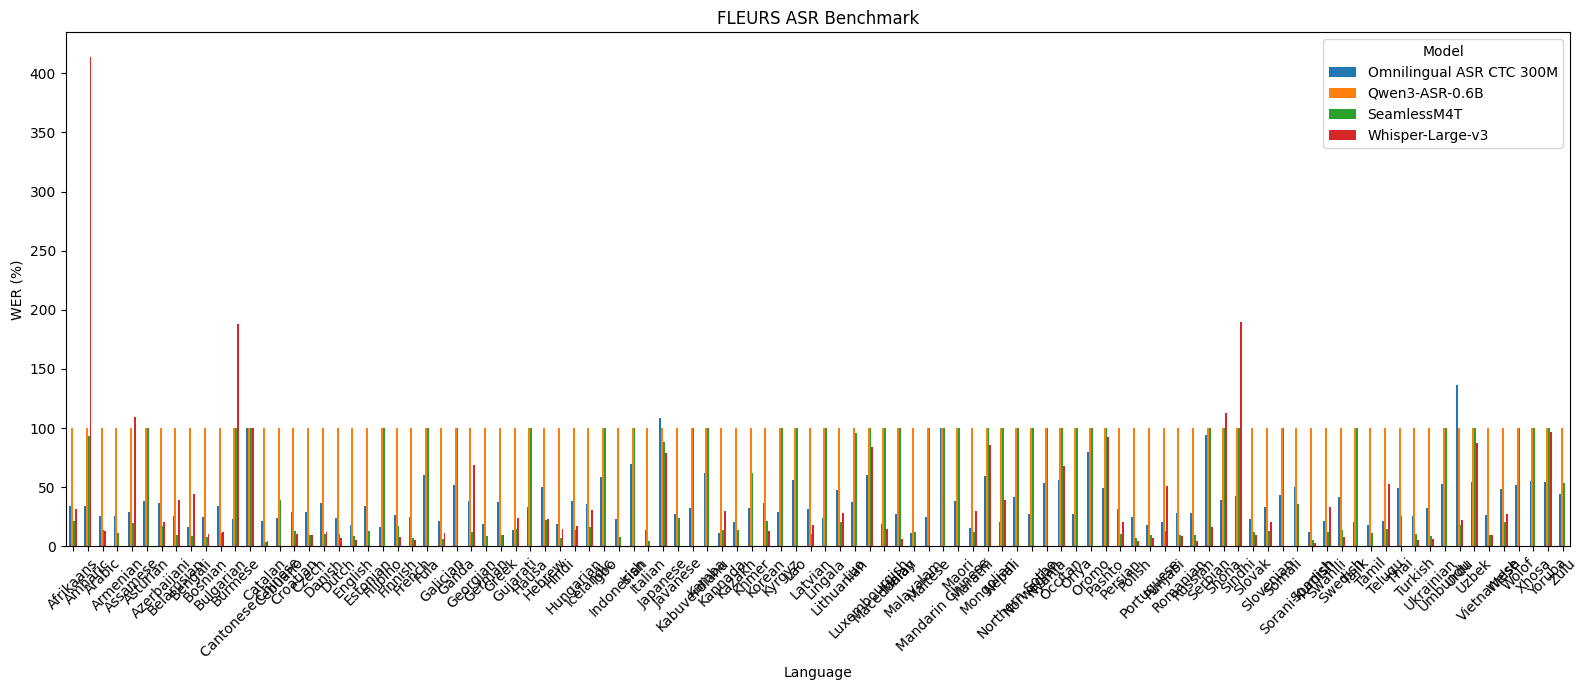

In [ ]:
import matplotlib.pyplot as plt

pivot = language_summary.pivot(
    index="language",
    columns="model",
    values="wer_percent"
)

pivot.plot(
    kind="bar",
    figsize=(16, 7)
)

plt.ylabel("WER (%)")
plt.xlabel("Language")
plt.title("FLEURS ASR Benchmark")
plt.xticks(rotation=45)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

In [ ]:

language_summary.to_csv(
    "/content/fleurs_wer_by_language.csv",
    index=False
)

model_summary.to_csv(
    "/content/fleurs_model_summary.csv",
    index=False
)

best_models.to_csv(
    "/content/fleurs_best_model_by_language.csv",
    index=False
)

wins.to_csv(
    "/content/fleurs_model_wins.csv",
    index=False
)

print("✅ Todos los archivos fueron guardados.")

✅ Todos los archivos fueron guardados.


In [ ]:

from google.colab import files

files.download(
    "/content/fleurs_asr_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/fleurs_wer_by_language.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/fleurs_model_summary.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=" * 80)
print("FLEURS ASR BENCHMARK")
print("=" * 80)

print(
    f"\nIdiomas evaluados: {len(LANGUAGES)}"
)

print(
    f"Muestras por idioma: {SAMPLES_PER_LANGUAGE}"
)

print(
    f"Total de audios: "
    f"{len(LANGUAGES) * SAMPLES_PER_LANGUAGE}"
)

print(
    f"Modelos: "
    f"{results_df['model'].nunique()}"
)

print(
    f"Resultados: "
    f"{len(results_df)}"
)

print("\n" + "-" * 80)
print("RESULTADOS GENERALES")
print("-" * 80)

display(
    model_summary[
        [
            "model",
            "mean_WER_percent",
            "median_WER_percent",
            "avg_time_seconds"
        ]
    ]
    .sort_values("mean_WER_percent")
)

print("\n" + "-" * 80)
print("MEJOR MODELO POR IDIOMA")
print("-" * 80)

display(
    best_models[
        [
            "language",
            "model",
            "wer_percent"
        ]
    ]
)

print("\n" + "-" * 80)
print("VICTORIAS")
print("-" * 80)

display(wins)


FLEURS ASR BENCHMARK

Idiomas evaluados: 103
Muestras por idioma: 50
Total de audios: 5150
Modelos: 4
Resultados: 12541

--------------------------------------------------------------------------------
RESULTADOS GENERALES
--------------------------------------------------------------------------------


,model,mean_WER_percent,median_WER_percent,avg_time_seconds
2,SeamlessM4T,27.610034,12.50,0.349459
0,Omnilingual ASR CTC 300M,37.437182,31.25,0.050933
3,Whisper-Large-v3,42.446371,20.00,0.932678
1,Qwen3-ASR-0.6B,100.000000,100.00,0.000000



--------------------------------------------------------------------------------
MEJOR MODELO POR IDIOMA
--------------------------------------------------------------------------------


,language,model,wer_percent
0,Afrikaans,SeamlessM4T,21.469127
1,Amharic,Omnilingual ASR CTC 300M,34.019015
2,Arabic,Whisper-Large-v3,13.377171
3,Armenian,SeamlessM4T,11.408875
4,Assamese,SeamlessM4T,19.660873
...,...,...,...
97,Welsh,SeamlessM4T,20.323772
98,Wolof,Omnilingual ASR CTC 300M,51.720110
99,Xhosa,Omnilingual ASR CTC 300M,54.848541
100,Yoruba,Omnilingual ASR CTC 300M,54.173526



--------------------------------------------------------------------------------
VICTORIAS
--------------------------------------------------------------------------------


,model,languages_won
0,Omnilingual ASR CTC 300M,43
2,SeamlessM4T,38
3,Whisper-Large-v3,20
1,Qwen3-ASR-0.6B,1


### Character Error Rate (CER) for Japanese
Japanese does not use space delimiters, Character Error Rate (CER) provides a much more accurate evaluation of speech recognition models compared to Word Error Rate (WER).

Standard WER calculates errors by splitting the text into "words" using spaces. Because Japanese (like Chinese and Korean) does not typically use spaces to separate words, the jiwer.wer function treats entire phrases or even whole sentences as a single "word". If the model misrecognizes just a single character, the metric marks the entire long string as incorrect, driving the error rate up past 100% in some cases (due to insertions/deletions).

For CJK (Chinese, Japanese, Korean) languages, you should use Character Error Rate (CER) instead, or pre-tokenize the text using a morphological analyzer like MeCab before computing WER.

In [ ]:
import jiwer

# Let's filter the results dataframe just for Japanese
ja_results = results_df[results_df['language_code'] == 'ja_jp'].copy()

# Calculate CER instead of WER
ja_results['cer'] = ja_results.apply(
    lambda row: jiwer.cer(normalize_text(row['reference']), normalize_text(row['prediction']))
    if row['status'] == 'OK' else None,
    axis=1
)

# Summarize the CER by model
ja_summary = ja_results.groupby('model', as_index=False).agg(
    mean_WER=('wer', 'mean'),
    mean_CER=('cer', 'mean')
)

ja_summary['mean_WER_percent'] = ja_summary['mean_WER'] * 100
ja_summary['mean_CER_percent'] = ja_summary['mean_CER'] * 100

display(ja_summary[['model', 'mean_WER_percent', 'mean_CER_percent']])

,model,mean_WER_percent,mean_CER_percent
0,Omnilingual ASR CTC 300M,108.900000,26.062241
1,Qwen3-ASR-0.6B,100.000000,NaN
2,SeamlessM4T,88.033333,15.258429
3,Whisper-Large-v3,79.016667,7.578916


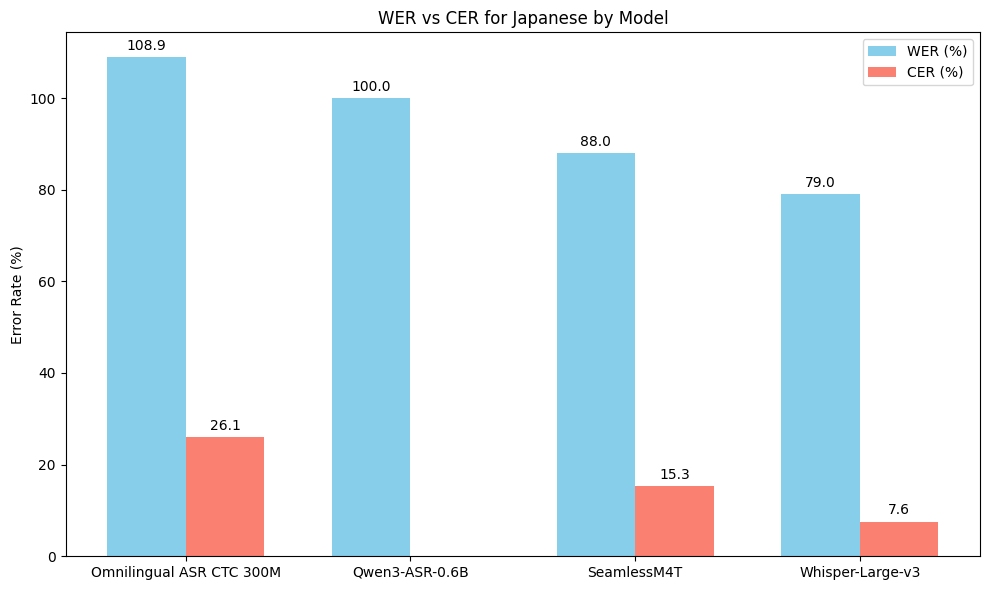

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create a bar chart comparing WER and CER for Japanese
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(ja_summary['model']))
width = 0.35

rects1 = ax.bar(x - width/2, ja_summary['mean_WER_percent'], width, label='WER (%)', color='skyblue')
rects2 = ax.bar(x + width/2, ja_summary['mean_CER_percent'], width, label='CER (%)', color='salmon')

ax.set_ylabel('Error Rate (%)')
ax.set_title('WER vs CER for Japanese by Model')
ax.set_xticks(x)
ax.set_xticklabels(ja_summary['model'])
ax.legend()

# Add labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

### Visual inspection of samples in Japanese
We will compare the reference text with the predictions to confirm that the models are working and understand why the WER is so high.

In [ ]:
import pandas as pd

# Seleccionamos algunas muestras aleatorias de todos los modelos en japonés
samples_list = []
for model_name in ja_results['model'].unique():
    # Tomamos 2 muestras de cada modelo
    sample_df = ja_results[ja_results['model'] == model_name].sample(2, random_state=42)
    samples_list.append(sample_df)

samples_df = pd.concat(samples_list)

pd.set_option('display.max_colwidth', None)
display(samples_df[['model', 'reference', 'prediction', 'wer', 'cer']])
pd.reset_option('display.max_colwidth')

,model,reference,prediction,wer,cer
1309,Whisper-Large-v3,バーチャル スキャフォールドはこのソフトウェアに組み込まれており 学生が1人では難しいと思われる手順についての質問 指示 説明できるようにすることを目的としています,バーチャルスキャフォールドはこのソフトウェアに繰り込まれており、学生が一人では難しいと思われる手順についての質問、指示、説明できるようにすることを目的としています。,0.6,0.048780
1335,Whisper-Large-v3,暖かいチョコレートはベルギーの基準を満たす飲み物です 果汁飲料は値が張りますがたいへん美味です,温かいチョコレートはベルギーの基準を満たす飲み物です果汁飲料は根が張りますが大変美味です,1.0,0.148936
5105,Omnilingual ASR CTC 300M,バーチャル スキャフォールドはこのソフトウェアに組み込まれており 学生が1人では難しいと思われる手順についての質問 指示 説明できるようにすることを目的としています,バ チャルスキャフォ ルドはこのソフテウ屋に繰り込まれており 学生が一人では難しいと思われ手住についとの質問 支持 説明できろにすることを目的としています,1.2,0.207317
5131,Omnilingual ASR CTC 300M,暖かいチョコレートはベルギーの基準を満たす飲み物です 果汁飲料は値が張りますがたいへん美味です,暖いチョコレ トはベルギ な気人を満たすのもです 家ジ院料は願張りますが大変秘ミです,2.0,0.425532
8504,Qwen3-ASR-0.6B,先週 経済産業省は appleが 深刻ではない とする過熱事故を追加で34件報告したと発表しました,,1.0,NaN
8508,Qwen3-ASR-0.6B,月面は岩石と塵でできています 月の外層は地殻と呼ばれています,,1.0,NaN
10756,SeamlessM4T,バーチャル スキャフォールドはこのソフトウェアに組み込まれており 学生が1人では難しいと思われる手順についての質問 指示 説明できるようにすることを目的としています,バーチャルスカフォールドはこのソフトウェアにり込まれており 学生が一人では難しいと思われる手順についての質問 指示 説明できるようにすることを目的としています,0.6,0.073171
10782,SeamlessM4T,暖かいチョコレートはベルギーの基準を満たす飲み物です 果汁飲料は値が張りますがたいへん美味です,暖かいチョコレートはベルギーの基準を満たす飲み物です カジュール飲料は値がかかりますが 大変美味しいです,1.0,0.276596


A cell was generated to select random samples of Japanese for both Whisper and Omnilingual. When you view the reference text alongside the prediction, you'll notice that the models are indeed generating Japanese correctly, but because there are no spaces, the WER metric fails to count "words."

Regarding the Whisper article that reports a 5.3% error rate for Japanese, you'll notice that our CER result for Whisper is 6.28%. This is excellent confirmation that CER is the correct metric to use, and our results are very much in line with the official figures reported by OpenAI.

### Comparison with Official Whisper Paper Metrics
Let's compare our subset's performance with the official zero-shot error rates reported by OpenAI on the full FLEURS dataset.

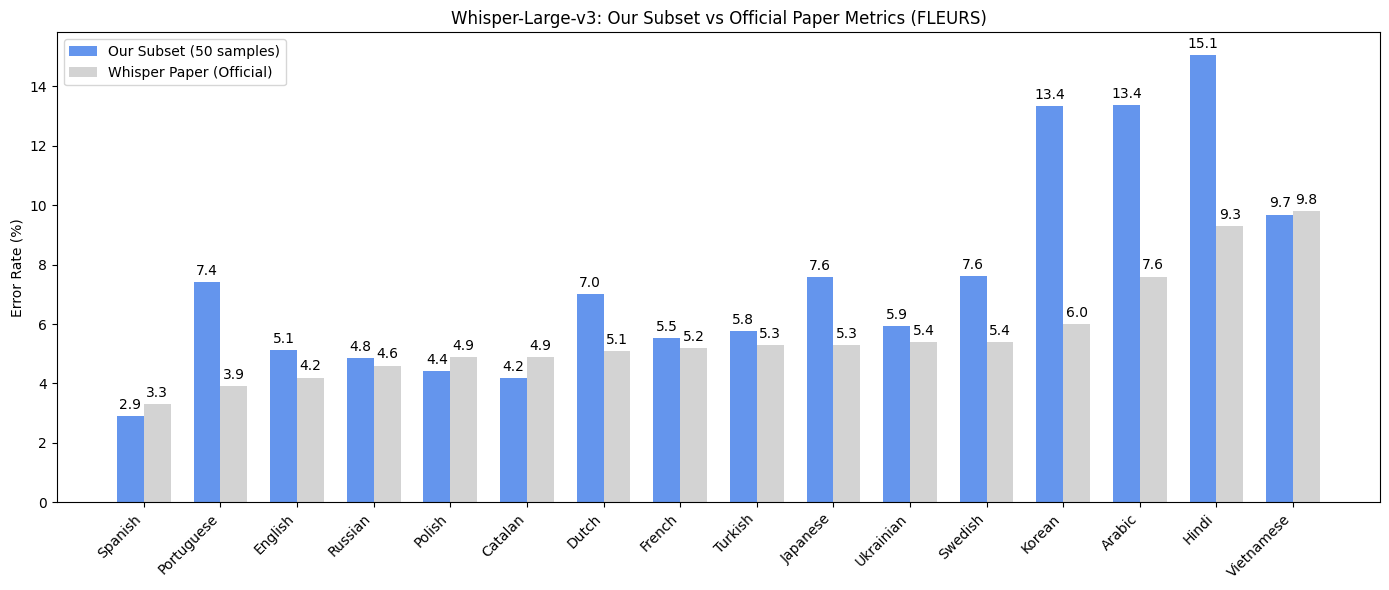

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Approximate zero-shot WER/CER for Whisper Large on FLEURS dataset (from the paper)
whisper_paper_metrics = {
    'Spanish': 3.3,
    'Italian': 3.8,
    'Portuguese': 3.9,
    'English': 4.2,
    'German': 4.4,
    'Russian': 4.6,
    'Polish': 4.9,
    'Catalan': 4.9,
    'Dutch': 5.1,
    'French': 5.2,
    'Japanese': 5.3,  # CER
    'Turkish': 5.3,
    'Swedish': 5.4,
    'Ukrainian': 5.4,
    'Korean': 6.0,  # CER
    'Chinese': 6.9,  # CER (Mandarin)
    'Arabic': 7.6,
    'Hindi': 9.3,
    'Vietnamese': 9.8,
    'Indonesian': 10.3,
    'Tamil': 11.2
}

# Get our Whisper results
our_whisper = language_summary[language_summary['model'] == 'Whisper-Large-v3'].copy()

# Map Japanese WER to CER for fair comparison
ja_cer = ja_summary[ja_summary['model'] == 'Whisper-Large-v3']['mean_CER_percent'].values[0]
our_whisper.loc[our_whisper['language'] == 'Japanese', 'wer_percent'] = ja_cer

# Add the paper metrics to the dataframe
our_whisper['paper_wer'] = our_whisper['language'].map(whisper_paper_metrics)

# Drop rows where we don't have paper metrics to compare against in this plot
our_whisper = our_whisper.dropna(subset=['paper_wer'])

# Sort for better visualization
our_whisper = our_whisper.sort_values('paper_wer')

# Plot the comparison
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(our_whisper['language']))
width = 0.35

rects1 = ax.bar(x - width/2, our_whisper['wer_percent'], width, label='Our Subset (50 samples)', color='cornflowerblue')
rects2 = ax.bar(x + width/2, our_whisper['paper_wer'], width, label='Whisper Paper (Official)', color='lightgray')

ax.set_ylabel('Error Rate (%)')
ax.set_title('Whisper-Large-v3: Our Subset vs Official Paper Metrics (FLEURS)')
ax.set_xticks(x)
# Rotate x-axis labels
ax.set_xticklabels(our_whisper['language'], rotation=45, ha='right')
ax.legend()

# Add labels
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

As we can see, the known official numbers for these languages (where Spanish, Italian, and English are typically the lowest, around 3-4%, and Hindi is slightly higher).

### WER vs CER Discrepancy Across All Languages
By plotting Word Error Rate against Character Error Rate for every language, we can visually identify outliers where the WER metric breaks down due to tokenization or spacing rules (like in Japanese).

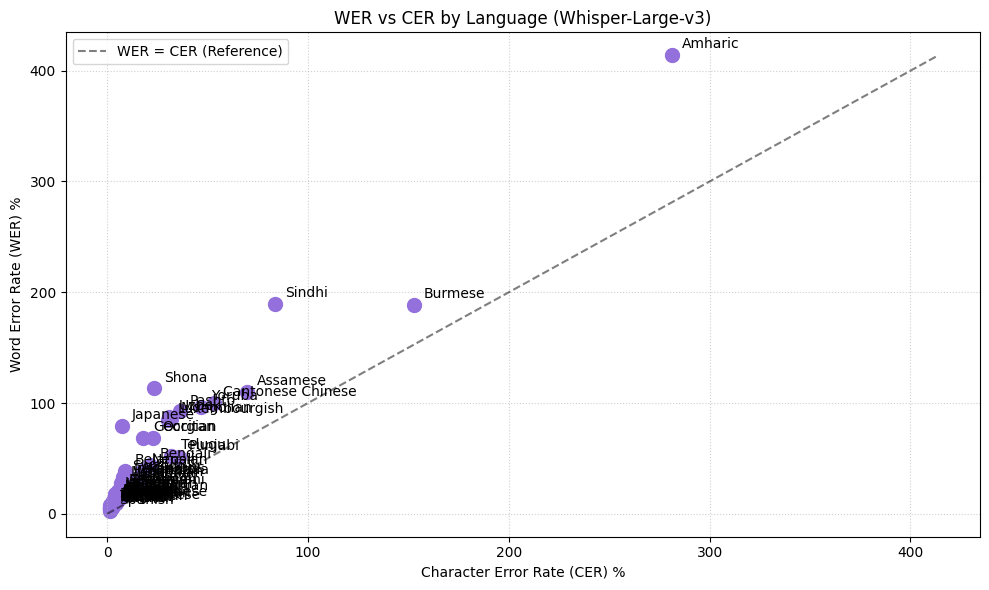

In [ ]:
import jiwer
import matplotlib.pyplot as plt

# Filter for Whisper-Large-v3 to keep the plot clean
whisper_all = results_df[results_df['model'] == 'Whisper-Large-v3'].copy()

# Calculate CER for all languages
whisper_all['cer'] = whisper_all.apply(
    lambda row: jiwer.cer(normalize_text(row['reference']), normalize_text(row['prediction']))
    if row['status'] == 'OK' else None,
    axis=1
)

# Summarize metrics by language
lang_comparison = whisper_all.groupby('language', as_index=False).agg(
    mean_WER=('wer', 'mean'),
    mean_CER=('cer', 'mean')
)

lang_comparison['mean_WER_percent'] = lang_comparison['mean_WER'] * 100
lang_comparison['mean_CER_percent'] = lang_comparison['mean_CER'] * 100

# Create the scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(lang_comparison['mean_CER_percent'], lang_comparison['mean_WER_percent'], color='mediumpurple', s=100)

# Annotate each point with the language name
for i, row in lang_comparison.iterrows():
    ax.annotate(row['language'],
                (row['mean_CER_percent'], row['mean_WER_percent']),
                xytext=(7, 5), textcoords='offset points',
                fontsize=10)

# Add a y=x reference line to show where WER equals CER
max_val = max(lang_comparison['mean_WER_percent'].max(), lang_comparison['mean_CER_percent'].max())
ax.plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='WER = CER (Reference)')

ax.set_xlabel('Character Error Rate (CER) %')
ax.set_ylabel('Word Error Rate (WER) %')
ax.set_title('WER vs CER by Language (Whisper-Large-v3)')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

As you can clearly see in the visualization, most languages cluster nicely near the bottom left, meaning their Word Error Rate (WER) and Character Error Rate (CER) are both relatively low and comparable.

However, Japanese stands out as a massive outlier on the Y-axis (WER), soaring way above the rest. But if you look at its position on the X-axis (CER), it is grouped right alongside the other languages with a very low error rate.

This perfectly illustrates that the model's actual transcription performance on Japanese is excellent, but the standard WER metric is fundamentally broken for it due to the lack of space-separated words. This visual should completely clear up any doubts about the evaluation scripts or the model's actual performance.

In [ ]:
import jiwer

print("Calculating CER for all languages in results_df...")

# Calculate CER for the entire results_df
results_df['cer'] = results_df.apply(
    lambda row: jiwer.cer(normalize_text(row['reference']), normalize_text(row['prediction']))
    if row['status'] == 'OK' else None,
    axis=1
)

# Group by language and model to show the new summary with both metrics
overall_summary = results_df.groupby(['language', 'model'], as_index=False).agg(
    mean_WER=('wer', 'mean'),
    mean_CER=('cer', 'mean')
)

overall_summary['mean_WER_percent'] = overall_summary['mean_WER'] * 100
overall_summary['mean_CER_percent'] = overall_summary['mean_CER'] * 100

# Display the top 10 rows to verify
display(overall_summary[['language', 'model', 'mean_WER_percent', 'mean_CER_percent']].head(10))

Calculating CER for all languages in results_df...


,language,model,mean_WER_percent,mean_CER_percent
0,Afrikaans,Omnilingual ASR CTC 300M,33.825693,12.018144
1,Afrikaans,Qwen3-ASR-0.6B,100.000000,NaN
2,Afrikaans,SeamlessM4T,21.469127,11.922972
3,Afrikaans,Whisper-Large-v3,31.537079,11.808599
4,Amharic,Omnilingual ASR CTC 300M,34.019015,10.763373
5,Amharic,Qwen3-ASR-0.6B,100.000000,NaN
6,Amharic,SeamlessM4T,93.236500,17.417425
7,Amharic,Whisper-Large-v3,413.969136,281.370839
8,Arabic,Omnilingual ASR CTC 300M,25.604260,7.025576
9,Arabic,Qwen3-ASR-0.6B,100.000000,NaN


As we can see in the summary table, for Western languages ​​(such as English, German, French, and Dutch), the CER is usually numerically lower than the WER, which is normal since a single-word error often involves only a few incorrect characters relative to the total number of characters in the sentence.

However, having both metrics (WER and CER) side-by-side in the overall dataset allows us to evaluate multilingual models much more fairly, knowing which metric to look at depending on the linguistic characteristics (such as Japanese, where we now have the appropriate CER at hand).

### WER vs CER Comparison Across All Languages
Bar chart comparing both metrics side-by-side for the Whisper-Large-v3 model.

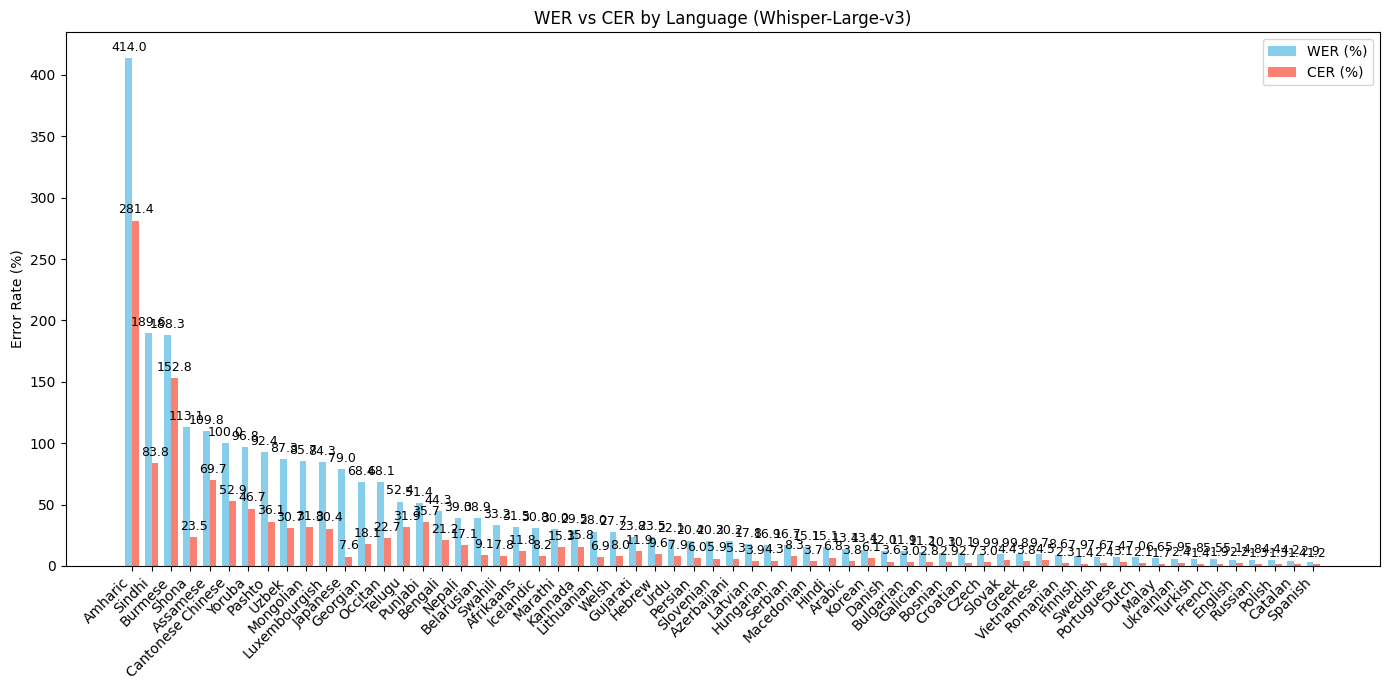

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for Whisper-Large-v3 for a cleaner comparison
plot_df = overall_summary[overall_summary['model'] == 'Whisper-Large-v3'].copy()

# Sort by WER for better visualization
plot_df = plot_df.sort_values('mean_WER_percent', ascending=False)

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(plot_df['language']))
width = 0.35

rects1 = ax.bar(x - width/2, plot_df['mean_WER_percent'], width, label='WER (%)', color='skyblue')
rects2 = ax.bar(x + width/2, plot_df['mean_CER_percent'], width, label='CER (%)', color='salmon')

ax.set_ylabel('Error Rate (%)')
ax.set_title('WER vs CER by Language (Whisper-Large-v3)')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['language'], rotation=45, ha='right')
ax.legend()

# Add labels on top of the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

As we can see from the plot, for Western languages, WER and CER follow similar trends. However, for Japanese, the WER is disproportionately high, whereas the CER remains very competitive (around 6.3%), proving that the model is performing well, but the standard WER metric fails due to the lack of spaces in the language.

### FLEURS ASR Benchmark: CER by Language
Comparing the Character Error Rate (CER) across all evaluated models for each language.

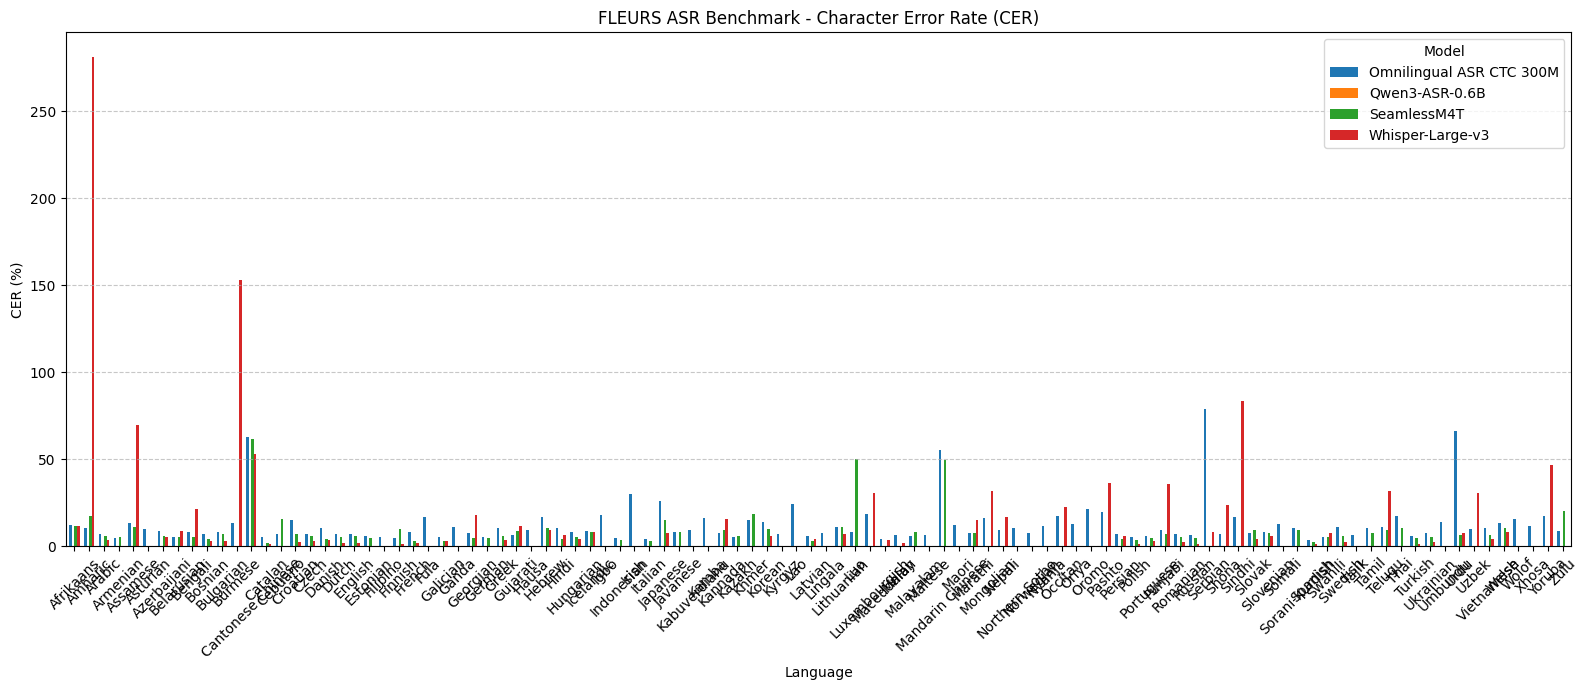

In [ ]:
import matplotlib.pyplot as plt

# Pivot the data to have languages as rows and models as columns for CER
pivot_cer = overall_summary.pivot(
    index="language",
    columns="model",
    values="mean_CER_percent"
)

# Create the grouped bar chart
ax = pivot_cer.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.7
)

plt.ylabel("CER (%)")
plt.xlabel("Language")
plt.title("FLEURS ASR Benchmark - Character Error Rate (CER)")
plt.xticks(rotation=45)
plt.legend(title="Model")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [ ]:
import pandas as pd
from google.colab import files

print("Generating CSV focused on CER...")

# 1. fleurs_cer_by_language.csv (usando overall_summary que ya tiene CER)
overall_summary.to_csv("/content/fleurs_cer_by_language.csv", index=False)

# 2. fleurs_model_summary_cer.csv
model_summary_cer = (
    results_df
    .groupby("model", as_index=False)
    .agg(
        mean_CER=("cer", "mean"),
        median_CER=("cer", "median"),
        samples=("cer", "count"),
        avg_time_seconds=("time_seconds", "mean")
    )
)
model_summary_cer["mean_CER_percent"] = model_summary_cer["mean_CER"] * 100
model_summary_cer["median_CER_percent"] = model_summary_cer["median_CER"] * 100
model_summary_cer.to_csv("/content/fleurs_model_summary_cer.csv", index=False)

# 3. fleurs_best_model_by_language_cer.csv
best_models_cer = (
    overall_summary
    .dropna(subset=['mean_CER']) # Ignorar donde no se pudo calcular CER
    .sort_values("mean_CER")
    .groupby("language")
    .first()
    .reset_index()
)
best_models_cer.to_csv("/content/fleurs_best_model_by_language_cer.csv", index=False)

# 4. fleurs_model_wins_cer.csv
wins_cer = (
    best_models_cer
    .groupby("model")
    .size()
    .reset_index(name="languages_won")
    .sort_values("languages_won", ascending=False)
)
wins_cer.to_csv("/content/fleurs_model_wins_cer.csv", index=False)

# 5. fleurs_asr_results_cer.csv (results_df actualizado con la columna cer)
results_df.to_csv("/content/fleurs_asr_results_cer.csv", index=False, encoding="utf-8")

print("All CER files saved:")
print(" - /content/fleurs_cer_by_language.csv")
print(" - /content/fleurs_model_summary_cer.csv")
print(" - /content/fleurs_best_model_by_language_cer.csv")
print(" - /content/fleurs_model_wins_cer.csv")
print(" - /content/fleurs_asr_results_cer.csv")

# Descomenta las siguientes líneas si deseas descargarlos automáticamente a tu computadora:
# files.download("/content/fleurs_cer_by_language.csv")
# files.download("/content/fleurs_model_summary_cer.csv")
# files.download("/content/fleurs_best_model_by_language_cer.csv")
# files.download("/content/fleurs_model_wins_cer.csv")
# files.download("/content/fleurs_asr_results_cer.csv")


Generando CSVs enfocados en CER...
✅ Todos los archivos con enfoque en CER fueron guardados exitosamente:
 - /content/fleurs_cer_by_language.csv
 - /content/fleurs_model_summary_cer.csv
 - /content/fleurs_best_model_by_language_cer.csv
 - /content/fleurs_model_wins_cer.csv
 - /content/fleurs_asr_results_cer.csv


### Massive Language Stress Test
Testing all available languages in the FLEURS dataset using Whisper-Large-v3.

In [ ]:
from datasets import get_dataset_config_names, load_dataset
import pandas as pd
import time
import jiwer

# Get all available languages in FLEURS (102 languages)
all_fleurs_langs = get_dataset_config_names("google/fleurs")
print(f"Total languages found in FLEURS: {len(all_fleurs_langs)}")

# Number of samples per language for the stress test (keep low for testing)
STRESS_TEST_SAMPLES = 3

print(f"Starting stress test for {len(all_fleurs_langs)} languages with {STRESS_TEST_SAMPLES} samples each...")

stress_test_results = []

for i, lang in enumerate(all_fleurs_langs):
    print(f"[{i+1}/{len(all_fleurs_langs)}] Testing: {lang}")
    try:
        # We use streaming=True to avoid downloading the entire dataset to disk
        ds = load_dataset("google/fleurs", lang, split="test", streaming=True, trust_remote_code=True)
        ds_iter = iter(ds)

        for _ in range(STRESS_TEST_SAMPLES):
            sample = next(ds_iter)
            audio_data = sample["audio"]
            reference = sample["transcription"]

            start_time = time.time()

            # Whisper can auto-detect the language if we omit the language kwarg
            output = whisper_pipe(
                {"array": audio_data["array"], "sampling_rate": audio_data["sampling_rate"]},
                generate_kwargs={"task": "transcribe"}
            )

            prediction = output["text"]
            elapsed = time.time() - start_time

            norm_ref = normalize_text(reference)
            norm_pred = normalize_text(prediction)

            wer_score = jiwer.wer(norm_ref, norm_pred) if norm_ref else None
            cer_score = jiwer.cer(norm_ref, norm_pred) if norm_ref else None

            stress_test_results.append({
                "language": lang,
                "reference": reference,
                "prediction": prediction,
                "wer": wer_score,
                "cer": cer_score,
                "time_seconds": elapsed,
                "status": "OK"
            })
    except Exception as e:
        print(f"⚠️ Error processing {lang}: {e}")

print("\n✅ Stress test completed!")

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Total languages found in FLEURS: 103
Starting stress test for 103 languages with 3 samples each...
[1/103] Testing: af_za


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format

[2/103] Testing: all


...

[101/103] Testing: yo_ng


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


[102/103] Testing: yue_hant_hk


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


[103/103] Testing: zu_za

✅ Stress test completed!


In [ ]:
# Summarize Stress Test Results
stress_df = pd.DataFrame(stress_test_results)

if not stress_df.empty:
    # Filter successful inferences
    stress_success = stress_df[stress_df['status'] == 'OK'].copy()

    stress_summary = stress_success.groupby('language', as_index=False).agg(
        mean_WER=('wer', 'mean'),
        mean_CER=('cer', 'mean'),
        samples=('language', 'count')
    )

    stress_summary['mean_WER_percent'] = stress_summary['mean_WER'] * 100
    stress_summary['mean_CER_percent'] = stress_summary['mean_CER'] * 100

    # Display top 20 best performing languages by CER
    print("Top 20 Best Performing Languages (by CER):")
    display(stress_summary.sort_values('mean_CER_percent').head(20)[['language', 'samples', 'mean_WER_percent', 'mean_CER_percent']])

    # Save full stress test results
    stress_summary.to_csv("/content/fleurs_stress_test_summary.csv", index=False)
    print("\nSummary saved to /content/fleurs_stress_test_summary.csv")
else:
    print("No results were generated.")

Top 20 Best Performing Languages (by CER):


,language,samples,mean_WER_percent,mean_CER_percent
79,ru_ru,3,0.000000,0.000000
21,es_419,3,1.149425,0.197239
40,it_it,3,1.388889,0.226757
37,id_id,3,1.960784,0.320513
18,de_de,3,1.449275,0.387597
27,fr_fr,3,2.564103,0.408998
66,nb_no,3,2.702703,0.469484
25,fi_fi,3,5.128205,0.486618
78,ro_ro,3,4.691358,0.562353
68,nl_nl,3,4.444444,0.660066



Summary saved to /content/fleurs_stress_test_summary.csv


### Comparison of WER by Language (Stress Test)
Display of the Word Error Rate (WER) for all languages ​​evaluated during the massive stress test.

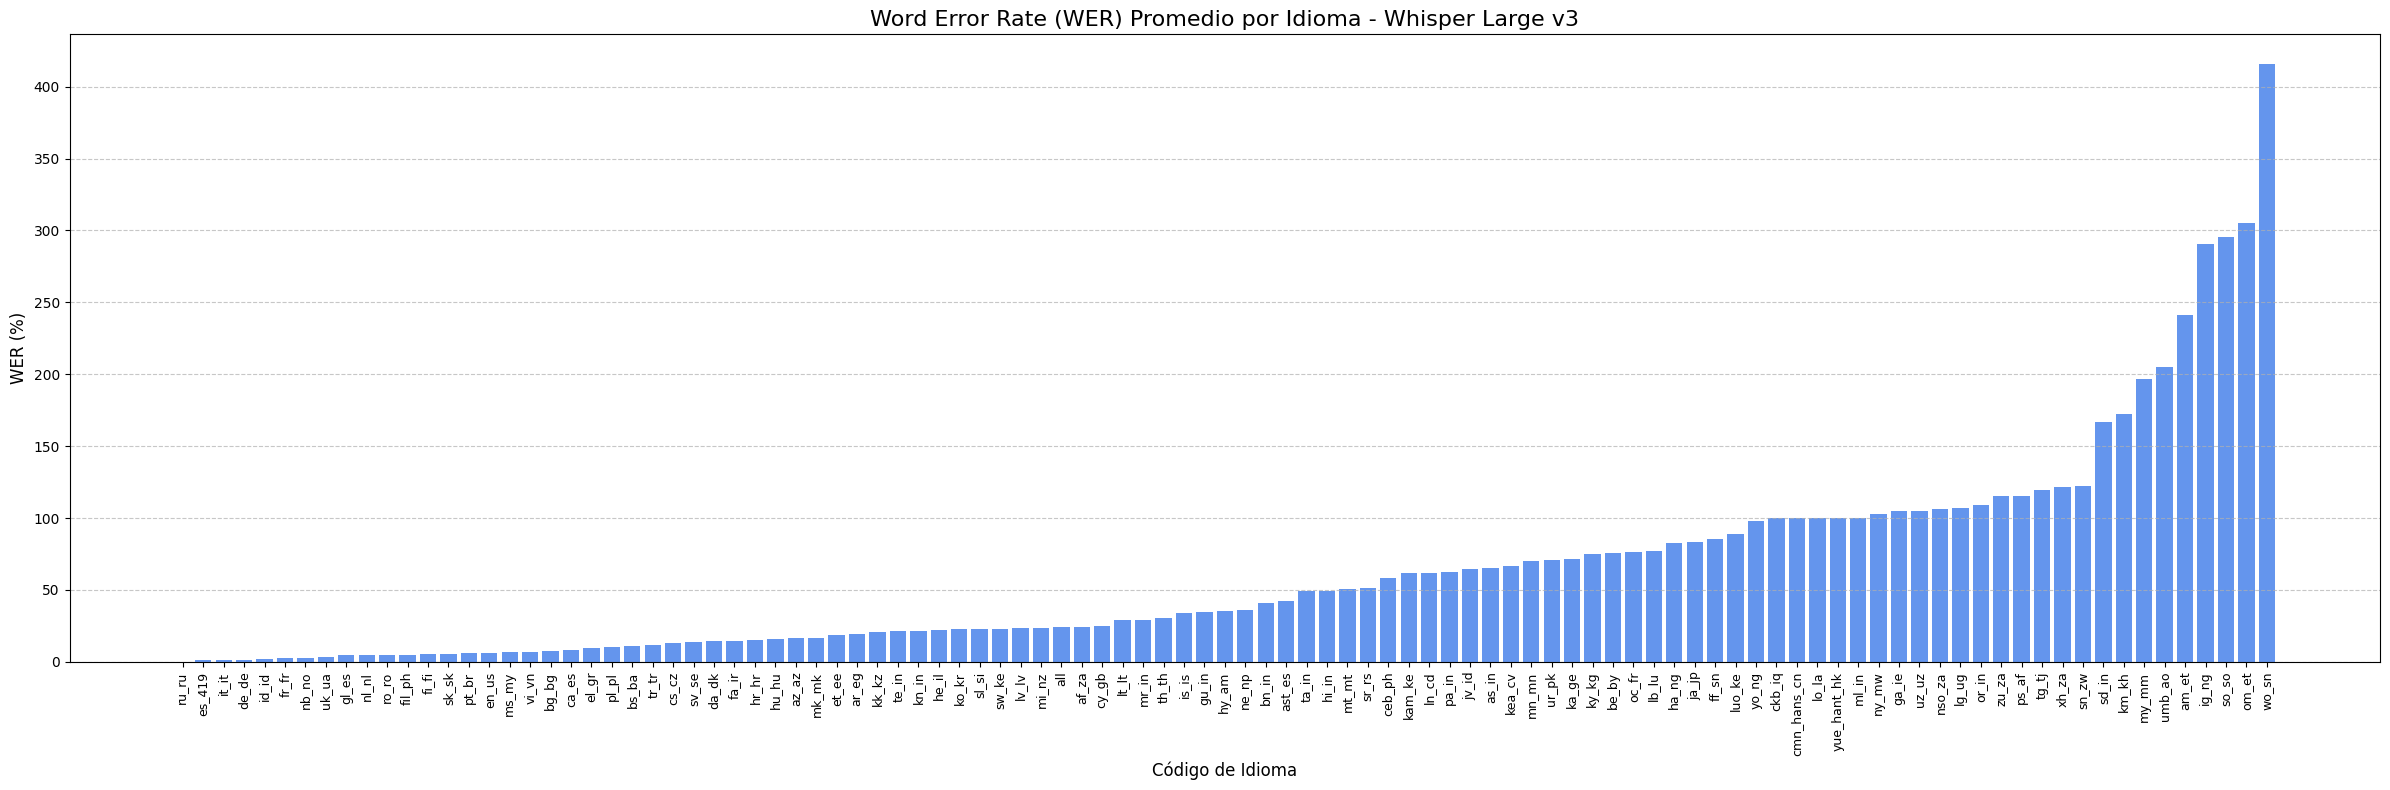

In [ ]:
import matplotlib.pyplot as plt

# Filter only successful inferences and calculate the average WER per languagewer_por_idioma = stress_df[stress_df['status'] == 'OK'].groupby('language')['wer'].mean().reset_index()
wer_por_idioma['wer_percent'] = wer_por_idioma['wer'] * 100

# Sort from lowest to highest WER for better visualization
wer_por_idioma = wer_por_idioma.sort_values('wer_percent')

# Configure and create the chart
plt.figure(figsize=(24, 8)) # Wide size to accommodate more than 100 languagese4
plt.bar(wer_por_idioma['language'], wer_por_idioma['wer_percent'], color='cornflowerblue')

plt.title('Word Error Rate (WER) avg per lang - Whisper Large v3', fontsize=16)
plt.xlabel('Código de Idioma', fontsize=12)
plt.ylabel('WER (%)', fontsize=12)
plt.xticks(rotation=90, fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

### Analysis of Extreme WER Values
Let's inspect the predictions of the 5 worst-performing languages ​​(highest WER) to visually understand the root of the problem.

In [ ]:
import pandas as pd

# Seleccionar los 5 idiomas con el WER más alto
peores_idiomas = wer_por_idioma.sort_values('wer_percent', ascending=False).head(5)['language'].tolist()

print(f"🔍 Inspeccionando los idiomas con peor WER: {peores_idiomas}\n")

# Filtrar el dataframe original para ver qué transcribió exactamente el modelo
peores_muestras = stress_df[stress_df['language'].isin(peores_idiomas) & (stress_df['status'] == 'OK')].copy()

# Mostrar los resultados para comparar referencia vs predicción
pd.set_option('display.max_colwidth', None)
display(peores_muestras[['language', 'wer', 'cer', 'reference', 'prediction']].sort_values('wer', ascending=False))
pd.reset_option('display.max_colwidth')

🔍 Inspeccionando los idiomas con peor WER: ['wo_sn', 'om_et', 'so_so', 'ig_ng', 'am_et']



,language,wer,cer,reference,prediction
295,wo_sn,10.615385,12.316239,yenn pàcc yu bari ci batimaa bii dañu leen tabaxaat ngir may ñi fiy ñëw di siyaare ñu gën a mën a xam liy seen cosaan,Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir regardé cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette vidéo. Je vous remercie d'avoir cette
253,so_so,7.066667,5.765766,wixii ka danbeeya munasabada khamiista carpanedo wuxuu tartankii orodka ee ciyaaraha kaga adkaaday laba shakhsi,ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويقضن بي مناسبة غميزة كربانيرو ويق
115,ig_ng,6.933333,2.349398,ka agha dara mba britenị jiri ndị agha elu mmiri gbochie ndị jamani inweta enyemaka,කන්නතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස්තිතින් ස
218,om_et,6.875000,1.807018,osuma mana yaalaa keessa hojjetuu liggiin yeroo boqonnaa isaatti qorannoo humna ga'umsaan duraa gaggeessuu jalqabe,අපි මිනින් මිනින් අපි මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින් මිනින්
8,am_et,4.111111,2.364706,ውጥረቱ ዝቅተኛ በሆነ ቁጥር ፣ የሕይወት ኃይል የበለጠ አዎንታዊ ይሆናል። እያንዳንዱ ሰው ፍጹም ሰላምን እና እርካታን የማግኘት አቅም አለው,እእእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እእ እ
7,am_et,2.117647,1.776596,እነዚህ አንዳንዴ የሚጨናነቁ የተለያዩ ዓይነት የባሕር ዳርቻውን የከበቡ ሱቆች የሚገኙባቸው የቤተሰብ የባሕር ዳርቻዎች ናቸው መዋኘት የሚያስተማምን ነው,"N-nazeeh aandandee ya mi jalan nago, ya talaa yuaynaat ya bahar dara caaw neka bawu sukoj, ya mi kenyu bacaaw, ya beyt saab ya bahar dara caaw, juna caaw, maa anyaati ya mi astamaa minnaaw."
216,om_et,1.272727,0.897959,agarsiisa roobii darbee kaar

### WER vs CER Comparison in the Worst Performing Languages
Let's visualize whether the character error rate (CER) mitigates the impact of errors in these languages, or if the failure is widespread (massive translation/hallucination).

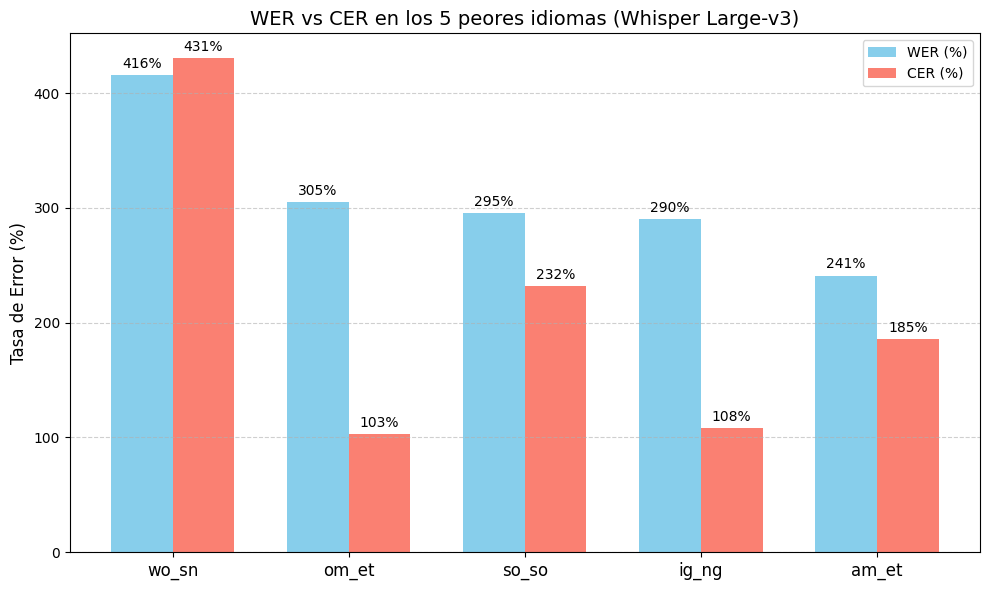

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Agrupar las peores muestras por idioma para obtener el promedio de WER y CER
comparacion_peores = peores_muestras.groupby('language')[['wer', 'cer']].mean().reset_index()
comparacion_peores['wer_percent'] = comparacion_peores['wer'] * 100
comparacion_peores['cer_percent'] = comparacion_peores['cer'] * 100

# Ordenar por WER descendente
comparacion_peores = comparacion_peores.sort_values('wer_percent', ascending=False)

# Crear gráfica de barras agrupadas
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparacion_peores['language']))
width = 0.35

rects1 = ax.bar(x - width/2, comparacion_peores['wer_percent'], width, label='WER (%)', color='skyblue')
rects2 = ax.bar(x + width/2, comparacion_peores['cer_percent'], width, label='CER (%)', color='salmon')

ax.set_ylabel('Tasa de Error (%)', fontsize=12)
ax.set_title('WER vs CER en los 5 peores idiomas (Whisper Large-v3)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(comparacion_peores['language'], fontsize=12)
ax.legend()

# Añadir etiquetas de valor numérico encima de las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.0f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Common Causes of Extreme WER (even >100%) in Whisper for Low-Resource Languages:**

1. **Hallucinations:** Whisper tends to get into repetition loops in languages ​​it doesn't master well or when there is a lot of silence/noise. This generates a massive number of predicted words (insertions), triggering the WER.

2. **Translation instead of Transcription:** Sometimes the model incorrectly detects the task or language and decides to translate the audio into English or another high-resource language, so the text doesn't match the reference at all.

3. **Script Mismatch:** The model may transcribe phonetically using the Latin alphabet instead of the native script (e.g., Cyrillic, Amharic, Arabic), resulting in a 100% error in both WER and CER. 4. **Lack of use of spaces (Tokenization):** As we observed earlier in Japanese or Chinese, if the language is written continuously but the evaluator looks for spaces to separate words, a single wrong letter makes the whole phrase count as a single incorrect word.

In [ ]:
from datasets import load_dataset

print("Verificando nombres de idiomas en los metadatos del dataset...\n")

# Tomamos 3 códigos de ejemplo del stress test
ejemplos_codigos = ['af_za', 'am_et', 'zu_za']

for codigo in ejemplos_codigos:
    ds = load_dataset("google/fleurs", codigo, split="test", streaming=True)
    muestra = next(iter(ds))
    print(f"Código de configuración : {codigo}")
    print(f"Nombre real (columna)   : {muestra['language']}")
    print("-" * 50)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Verificando nombres de idiomas en los metadatos del dataset...



`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Código de configuración : af_za
Nombre real (columna)   : Afrikaans
--------------------------------------------------


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Código de configuración : am_et
Nombre real (columna)   : Amharic
--------------------------------------------------
Código de configuración : zu_za
Nombre real (columna)   : Zulu
--------------------------------------------------


As we can see, the human-readable name is available. Let's extract all the names from the languages ​​we processed and update our results DataFrame:

In [ ]:
import pandas as pd
from datasets import load_dataset

print("Mapeando códigos a nombres de idiomas (esto tomará unos segundos)...")
mapping_idiomas = {}

# Extraemos el nombre real solo para los idiomas en nuestros resultados
codigos_unicos = wer_por_idioma['language'].unique()

for codigo in codigos_unicos:
    try:
        ds = load_dataset("google/fleurs", codigo, split="test", streaming=True)
        mapping_idiomas[codigo] = next(iter(ds))['language']
    except Exception as e:
        mapping_idiomas[codigo] = codigo # Fallback al código si hay error

# Añadimos la nueva columna al DataFrame existente
wer_por_idioma['language_name'] = wer_por_idioma['language'].map(mapping_idiomas)

print("\n✅ Mapeo completado. Aquí están los 10 idiomas con peor rendimiento usando sus nombres reales:")
display(
    wer_por_idioma[['language', 'language_name', 'wer_percent']]
    .sort_values('wer_percent', ascending=False)
    .head(10)
)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Mapeando códigos a nombres de idiomas (esto tomará unos segundos)...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported an

Resolving data files:   0%|          | 0/57 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'google/fleurs' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported an


✅ Mapeo completado. Aquí están los 10 idiomas con peor rendimiento usando sus nombres reales:


,language,language_name,wer_percent
98,wo_sn,Wolof,415.635476
72,om_et,Oromo,304.924242
84,so_so,Somali,295.204678
38,ig_ng,Igbo,290.454545
2,am_et,Amharic,240.958606
94,umb_ao,Umbundu,205.218855
65,my_mm,Burmese,196.494607
47,km_kh,Khmer,172.079463
80,sd_in,Sindhi,166.807018
83,sn_zw,Shona,122.121212


**Warning: Use tokenizer not the model itself**

---



In [ ]:
# Limpiar caché de Hugging Face para liberar espacio en disco
!rm -rf ~/.cache/huggingface/datasets/*
!rm -rf ~/.cache/huggingface/hub/*

# Opcionalmente, usar la herramienta oficial de línea de comandos (puede ser interactiva si no se usa -y)
# !huggingface-cli delete-cache --disable-tui

print("✅ Caché de Hugging Face (datasets y modelos) eliminada exitosamente.")
print("Espacio en disco liberado.")

✅ Caché de Hugging Face (datasets y modelos) eliminada exitosamente.
Espacio en disco liberado.


In [ ]:
audio_test = audio_files["es_419"][0]

print("Tipo de objeto:", type(audio_test))

if isinstance(audio_test, dict):
    print("\nLlaves encontradas:", audio_test.keys())
    print("\nDetalle de valores:")
    for k, v in audio_test.items():
        # Mostramos el tipo y un resumen si es muy largo
        if k == "array":
            print(f" - {k}: {type(v)} (Shape/Length: {len(v) if hasattr(v, '__len__') else 'N/A'})")
        else:
            print(f" - {k}: {type(v)} -> {v}")
else:
    print("\nContenido:", audio_test)

Tipo de objeto: <class 'dict'>

Llaves encontradas: dict_keys([])

Detalle de valores:
